# Distance Space — Where Amb Pooling Fails

Every run as a dot: own R1 distance on x, neighbor R1 distance on y.
Red = pooling does not help (delta >= 0). Green = pooling helps.

In [40]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(_root / "data_cluster" / "resource_grid" / "results.csv")
df = df[df["n_amb_r1_to_ccp"] == 2].reset_index(drop=True)
print(f"Loaded {len(df)} runs (filtered n_amb==2)")

# Split into policies
stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]
amb   = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)]
fac   = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)]
both  = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)]
print(f"Per policy: stove={len(stove)}, amb={len(amb)}, fac={len(fac)}, both={len(both)}")
print(f"bcas rates: {sorted(df['bcas_rate'].unique())}")

Loaded 405600 runs (filtered n_amb==2)
Per policy: stove=101400, amb=101400, fac=101400, both=101400
bcas rates: [np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07)]


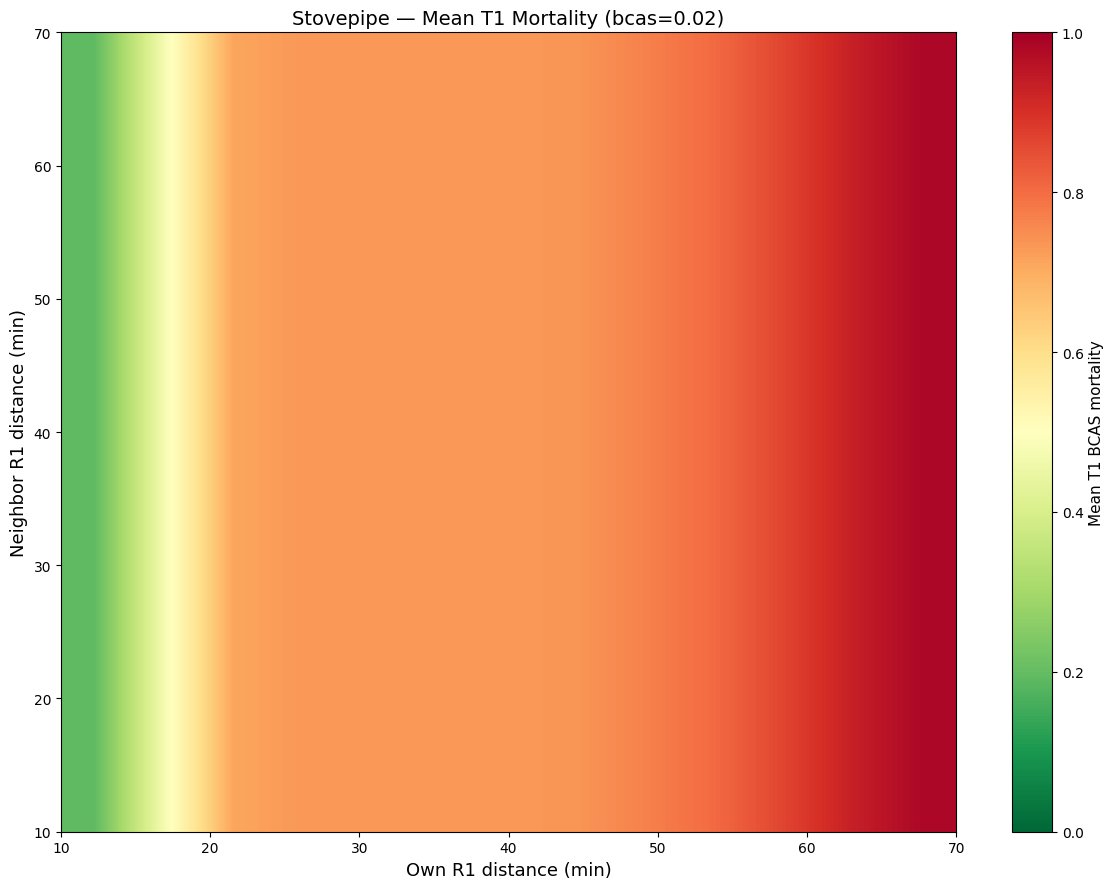

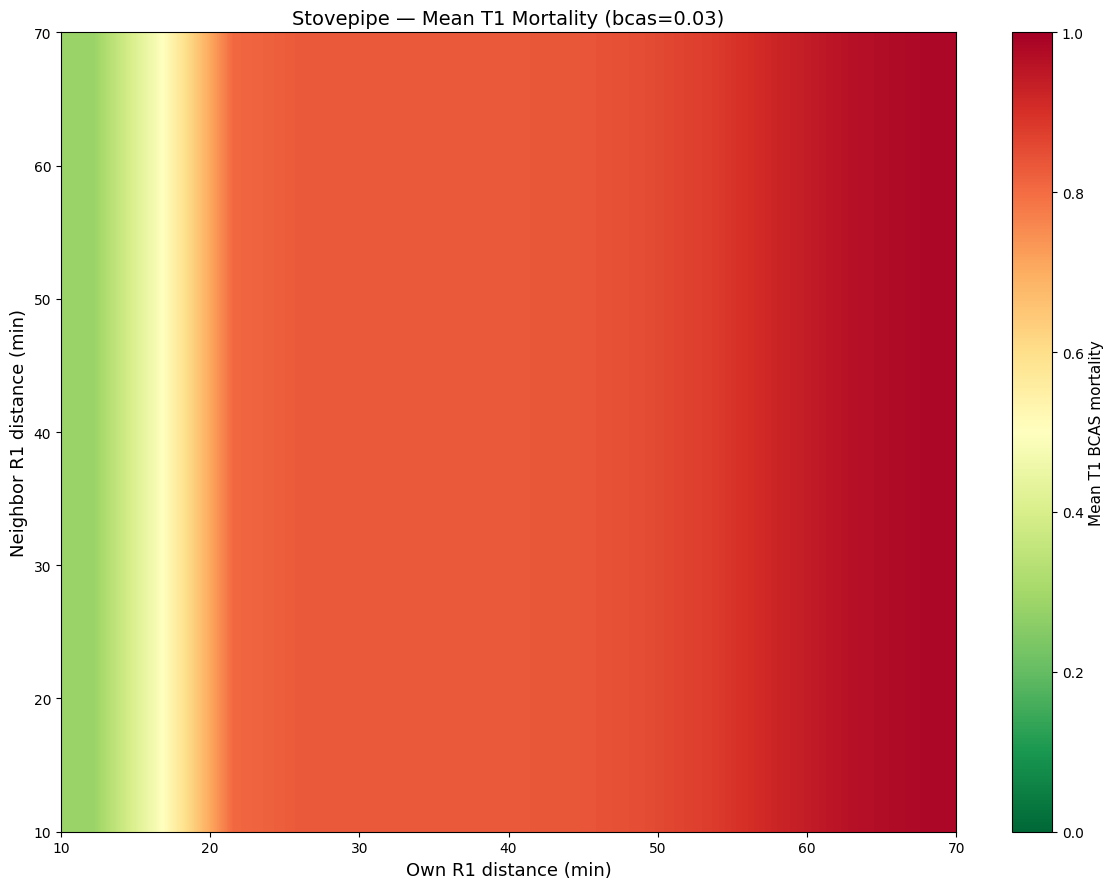

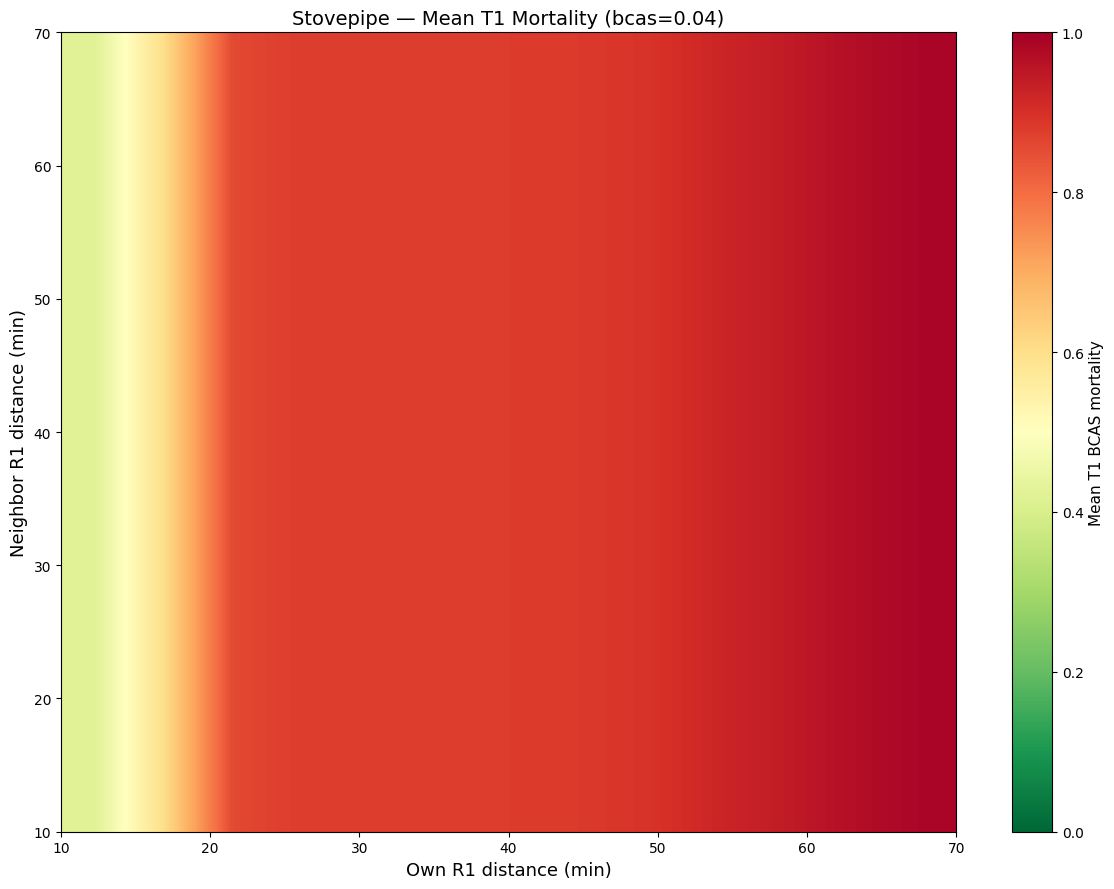

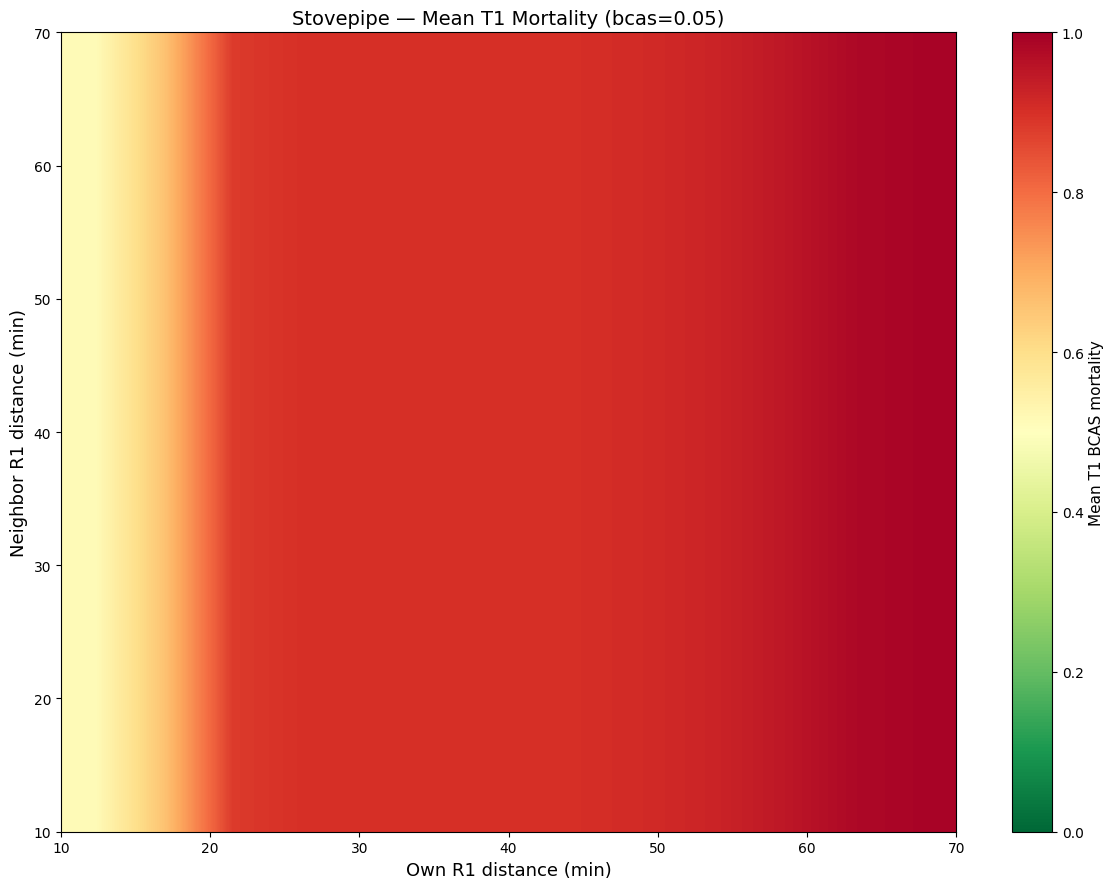

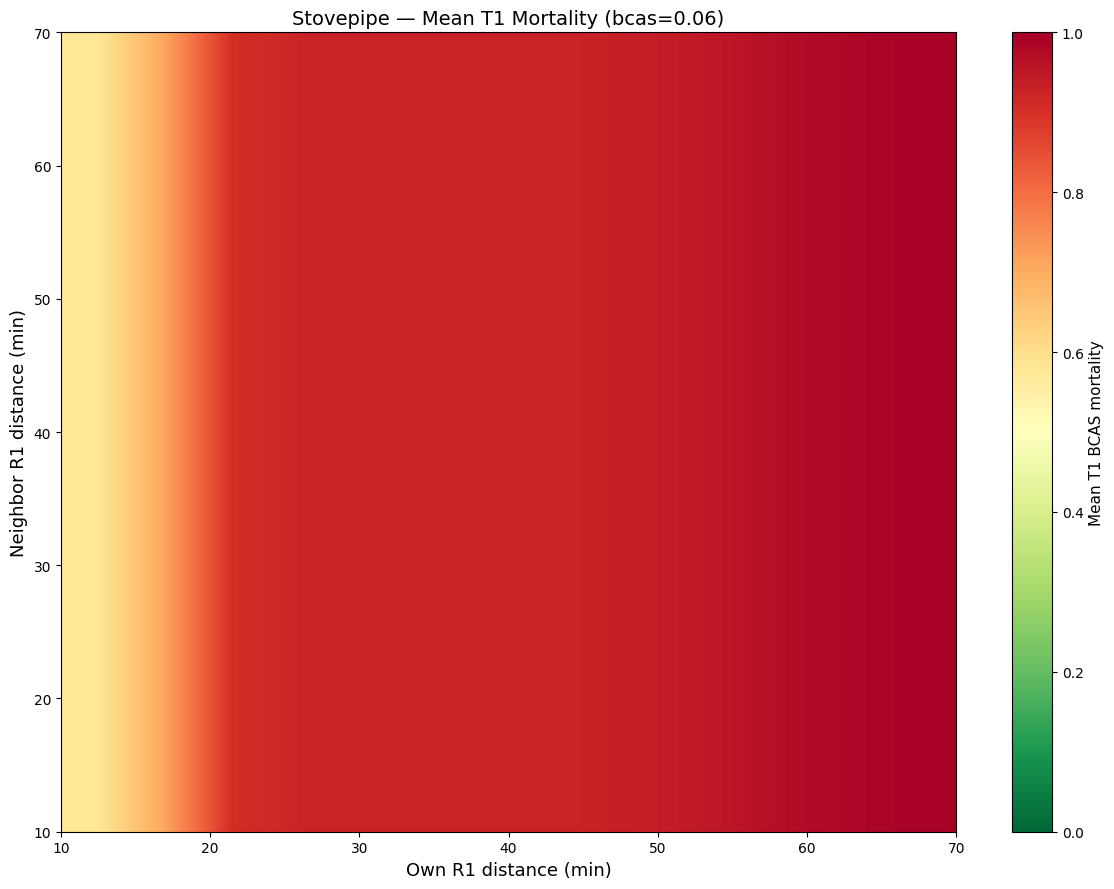

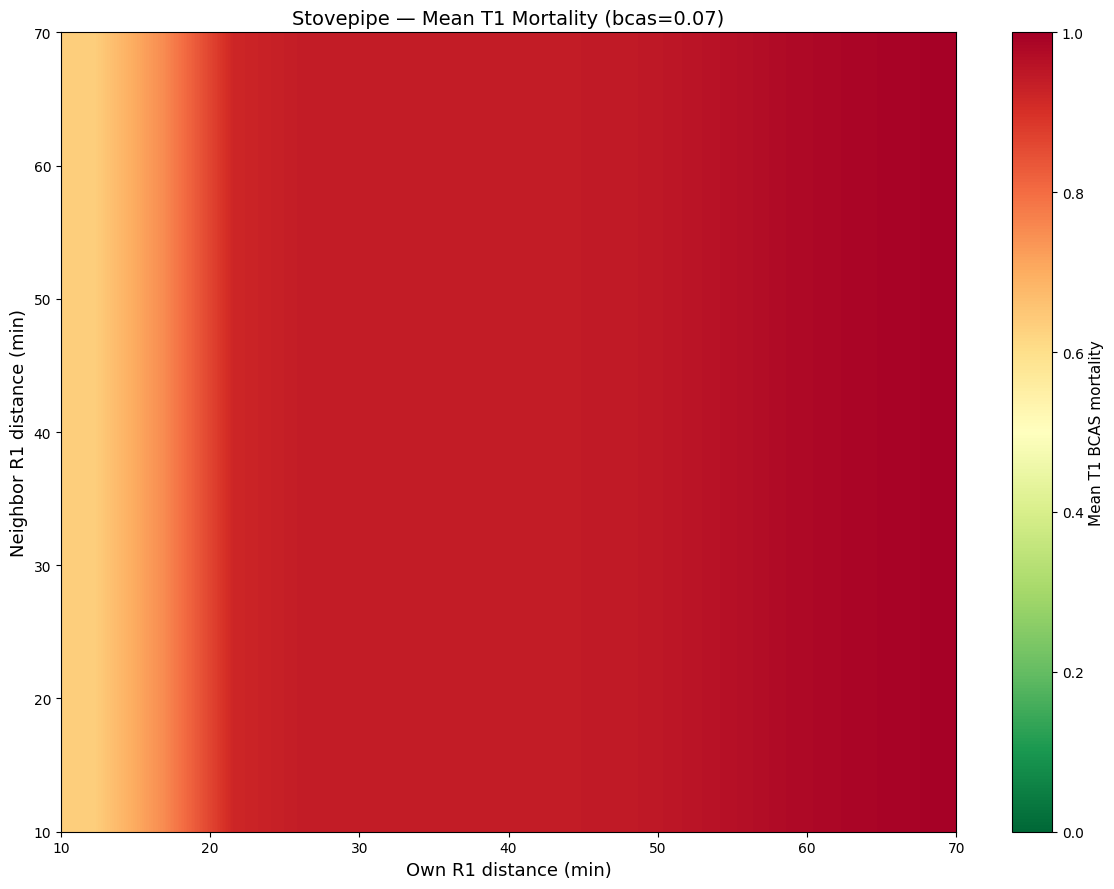

In [41]:
# Smooth heatmap — stovepipe mortality per bcas
for bcas in sorted(df["bcas_rate"].unique()):
    sub = stove[stove["bcas_rate"] == bcas]
    grid = sub.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].mean().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="death_rate_T1_BCAS")

    fig, ax = plt.subplots(figsize=(12, 9))
    im = ax.imshow(pivot.values, cmap="RdYlGn_r", origin="lower", aspect="auto",
                   interpolation="bilinear", vmin=0, vmax=1,
                   extent=[pivot.columns.min(), pivot.columns.max(),
                           pivot.index.min(), pivot.index.max()])
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Stovepipe — Mean T1 Mortality (bcas={bcas})", fontsize=14)
    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Mean T1 BCAS mortality", fontsize=11)
    plt.tight_layout()
    plt.show()

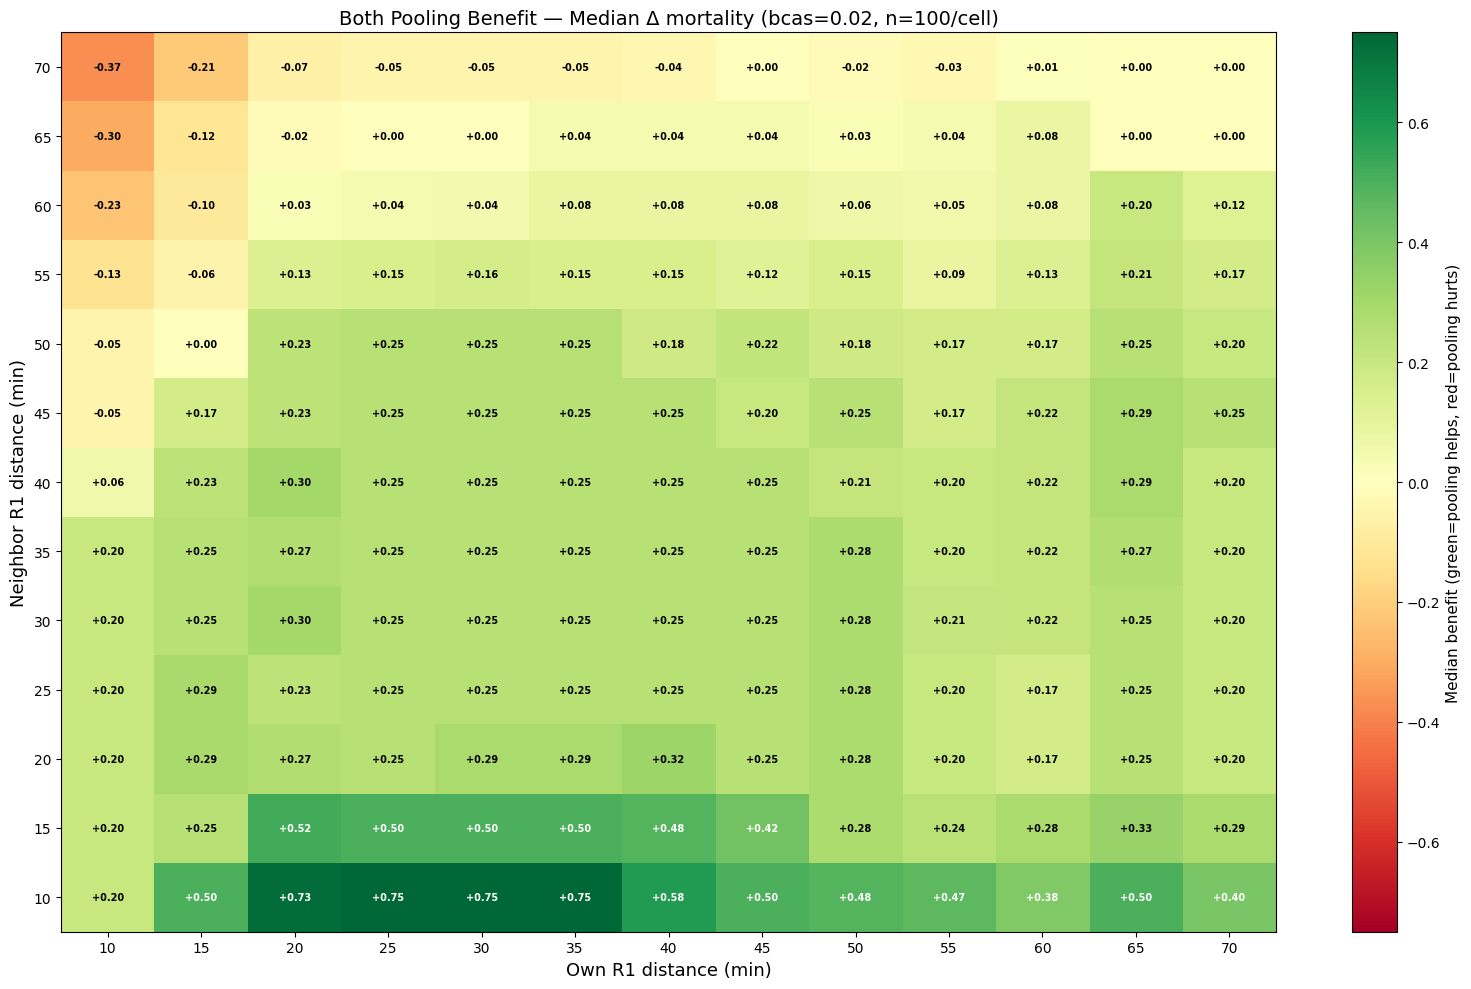

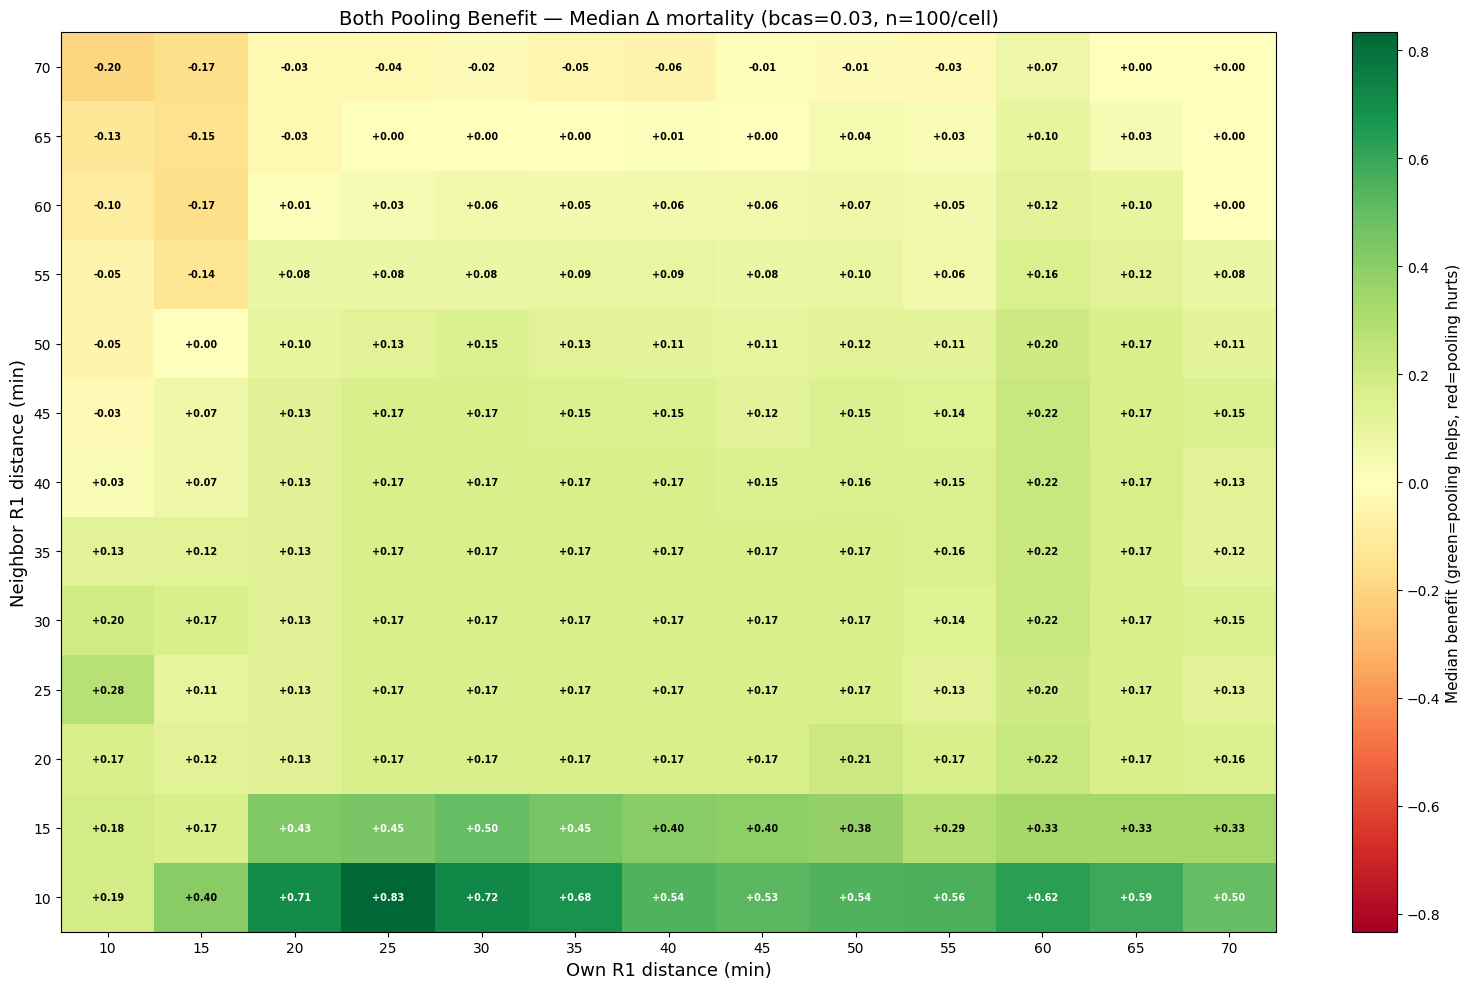

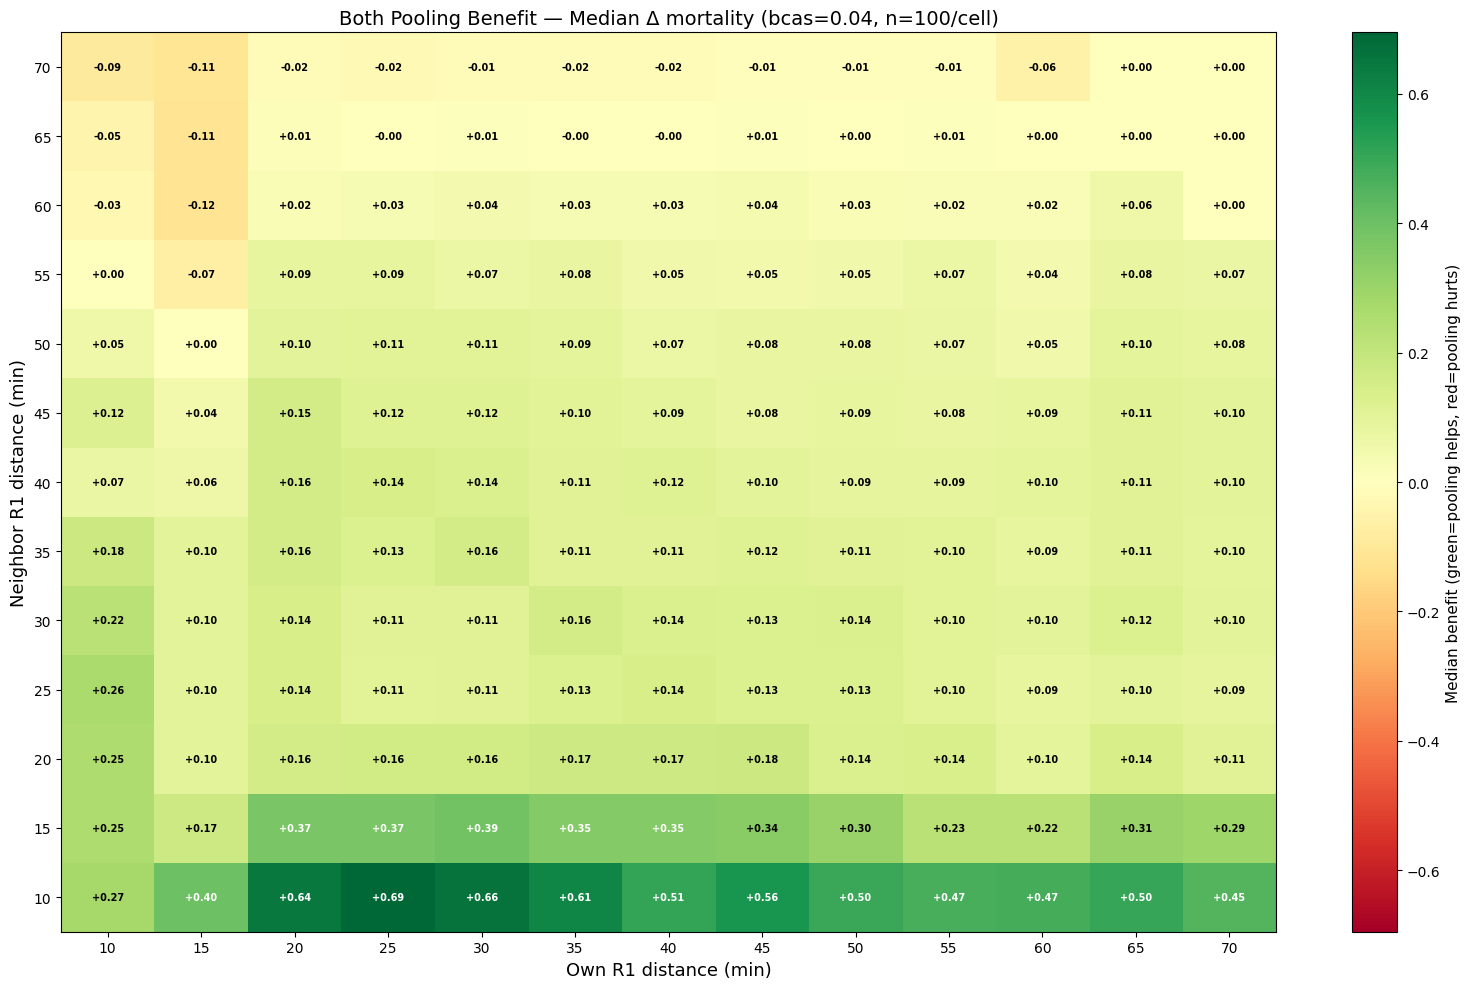

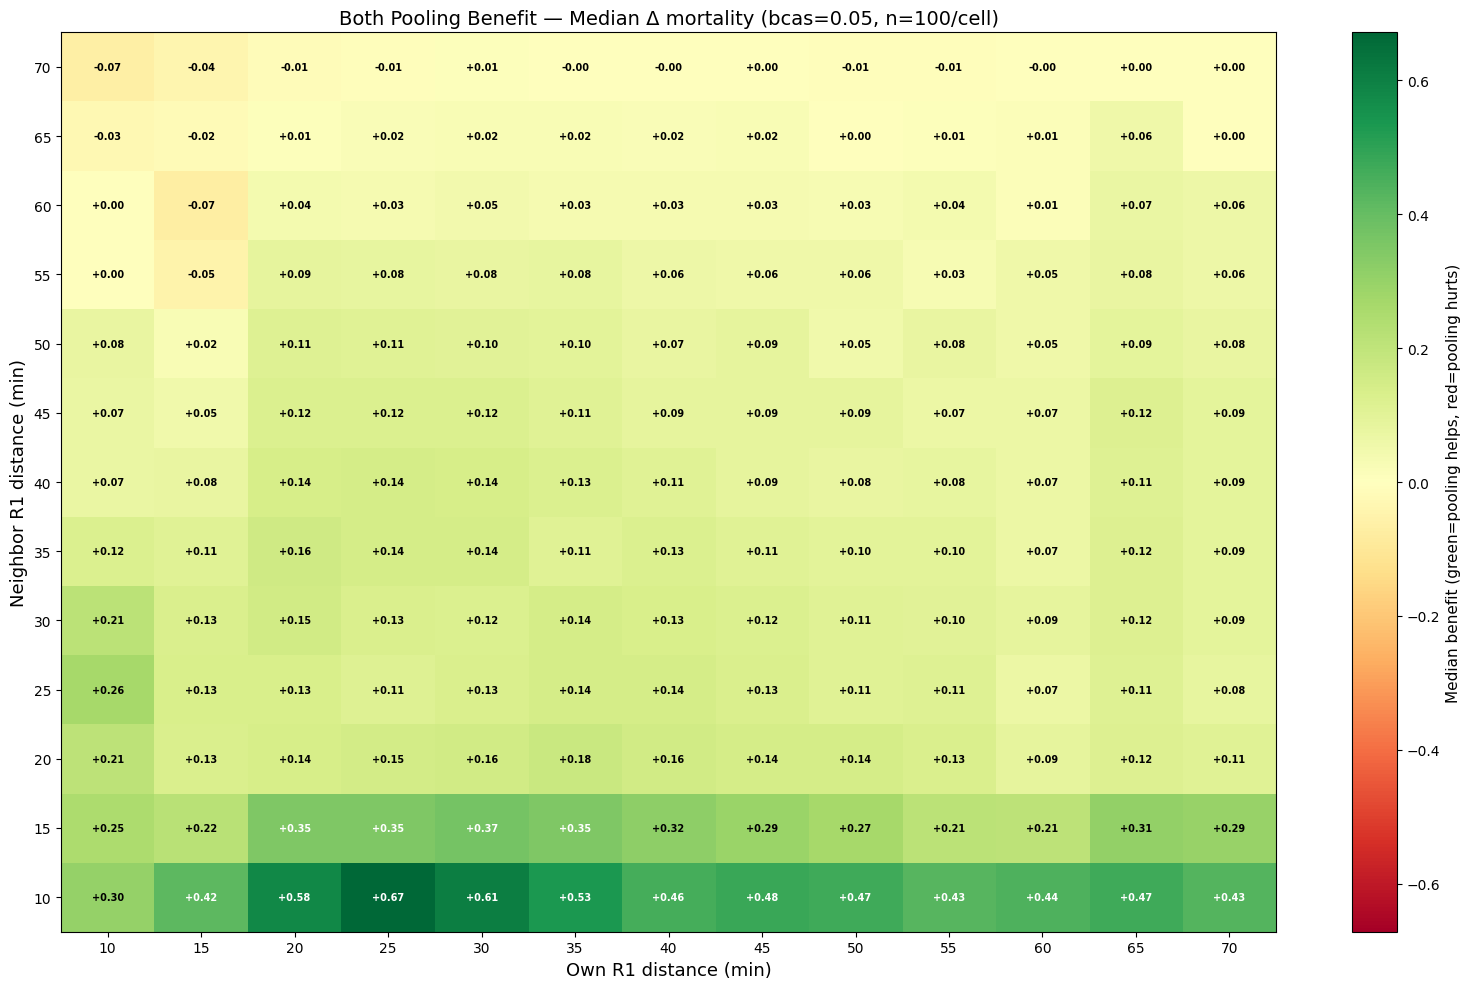

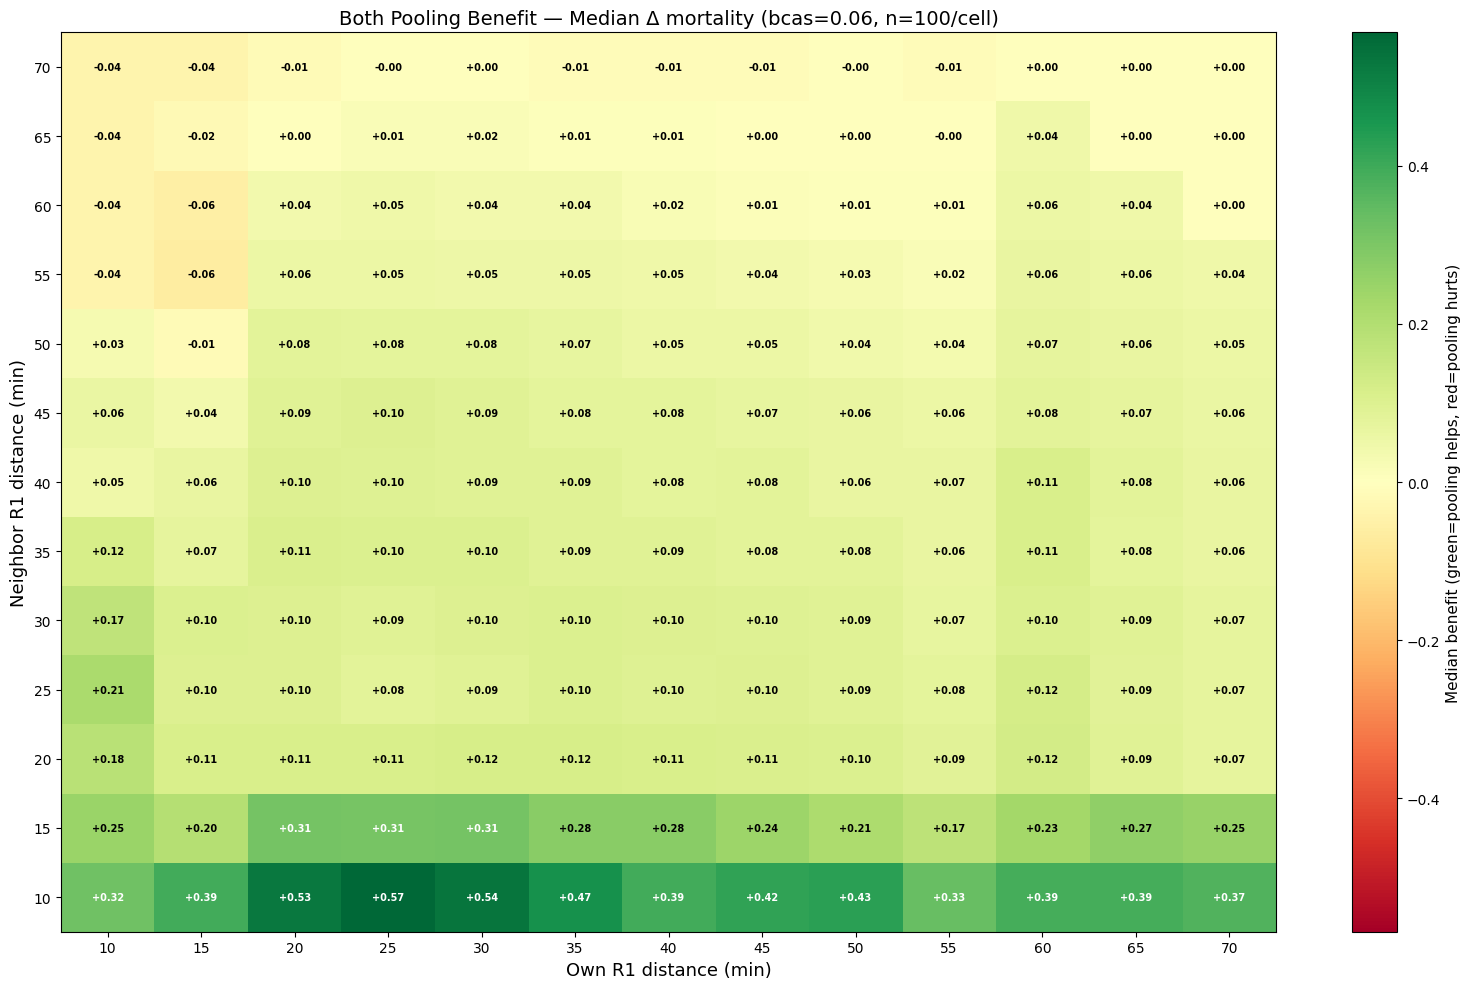

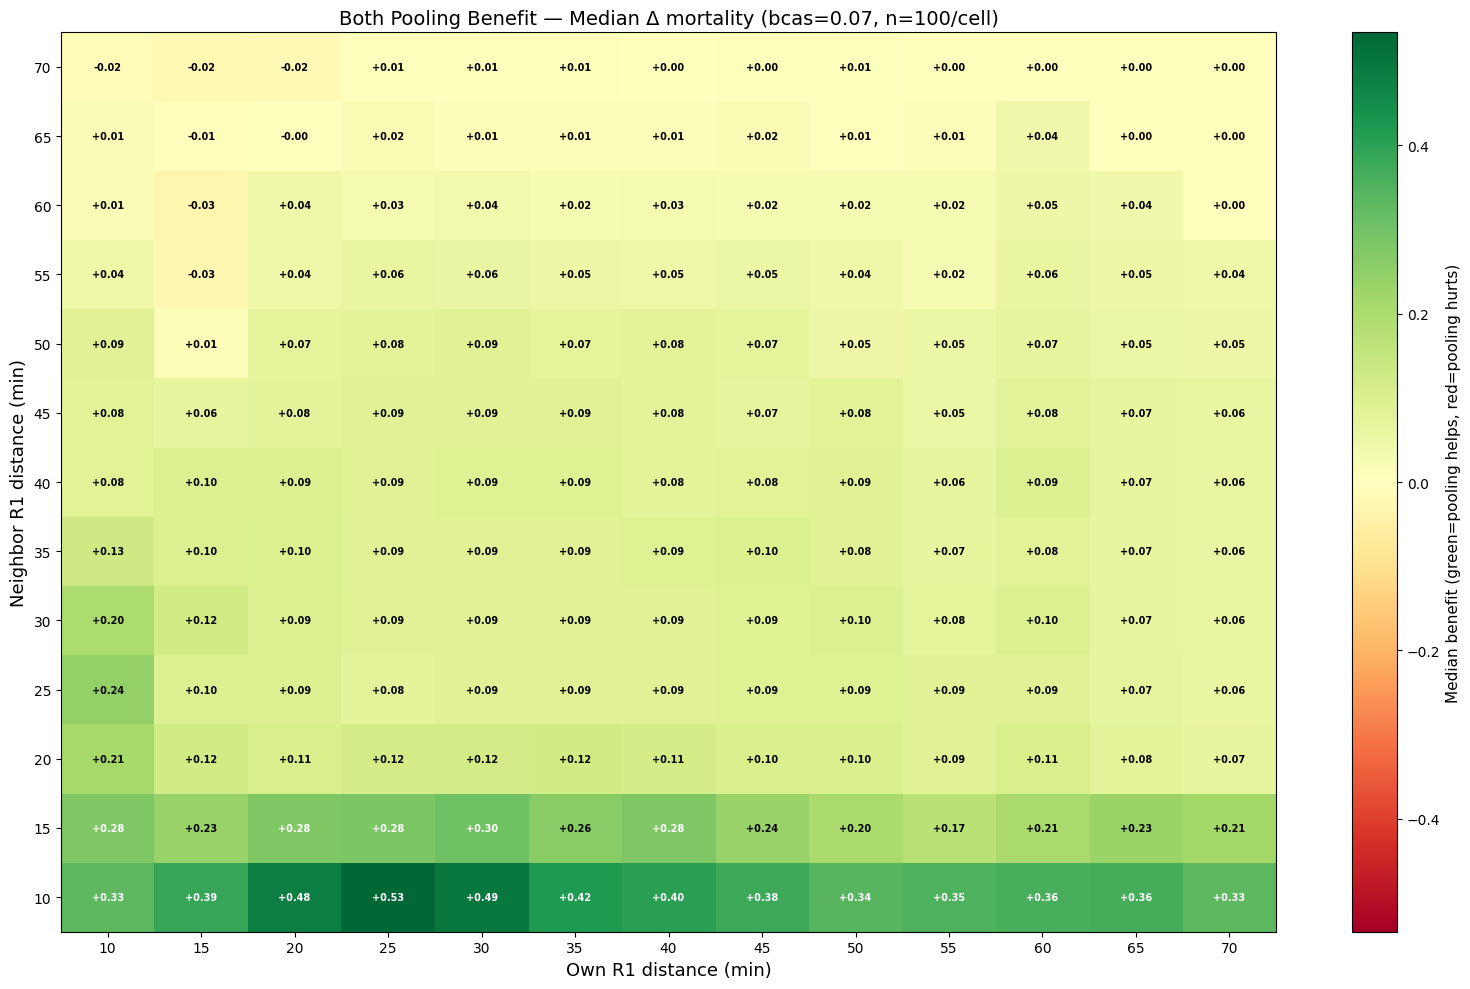

In [42]:
# Grid with median values — pooling benefit (stove - both) per bcas
for bcas in sorted(df["bcas_rate"].unique()):
    s = stove[stove["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    b = both[both["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    benefit = (s - b).reset_index()
    benefit.columns = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "benefit"]
    pivot = benefit.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="benefit")

    vmax = max(abs(pivot.values.min()), abs(pivot.values.max()))

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="RdYlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=-vmax, vmax=vmax)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Both Pooling Benefit — Median Δ mortality (bcas={bcas}, n=100/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if abs(val) > vmax * 0.5 else "black"
            ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median benefit (green=pooling helps, red=pooling hurts)", fontsize=11)
    plt.tight_layout()
    plt.show()

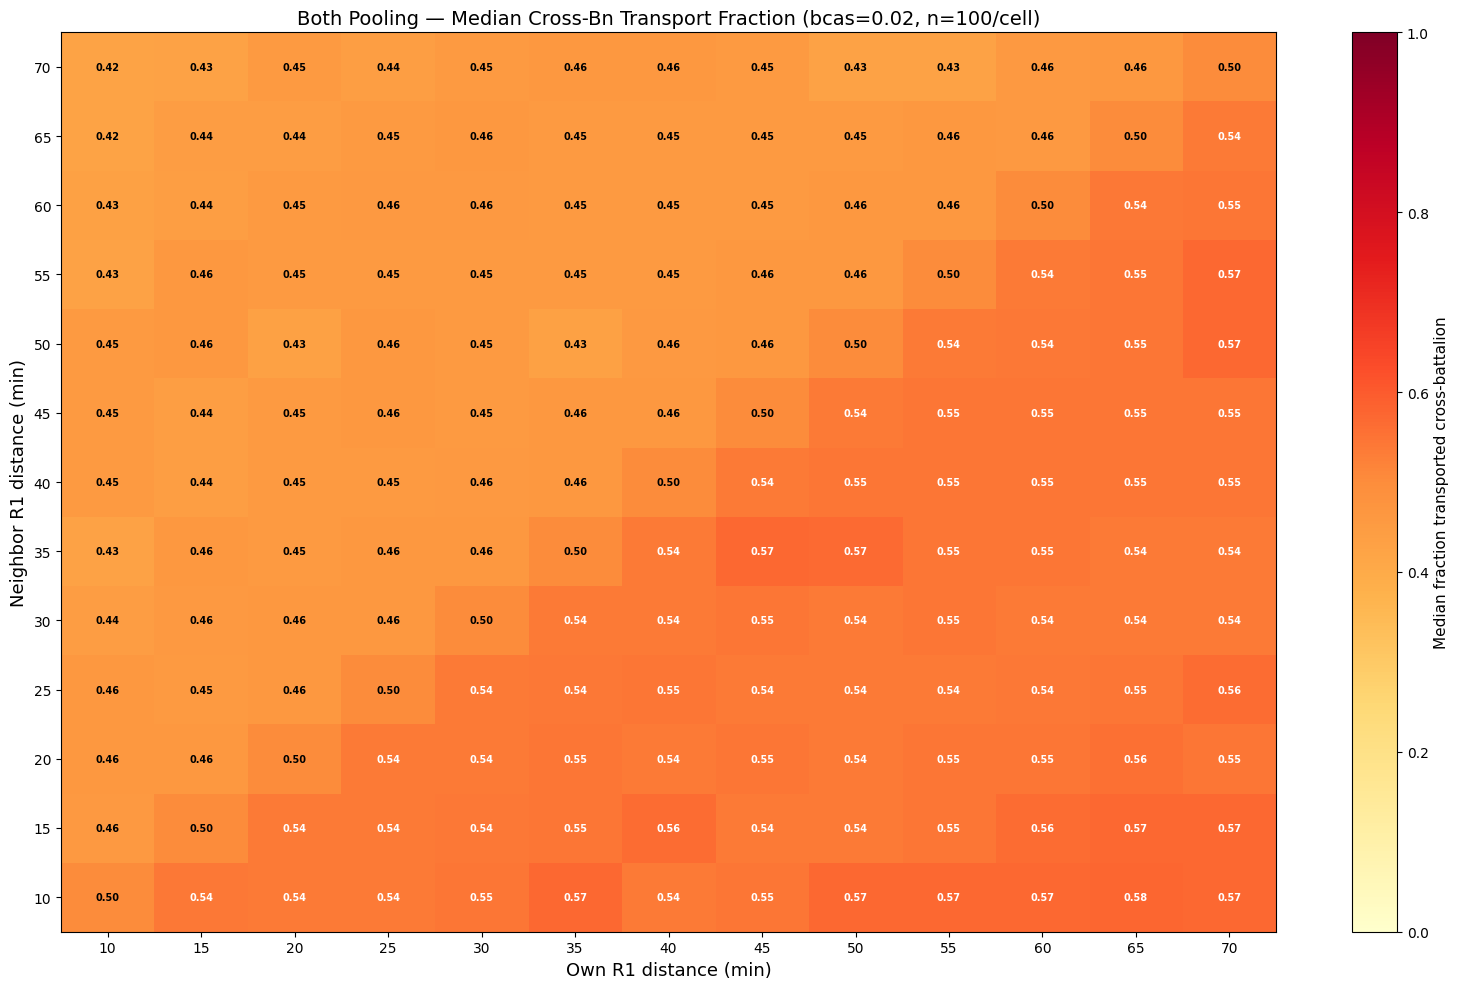

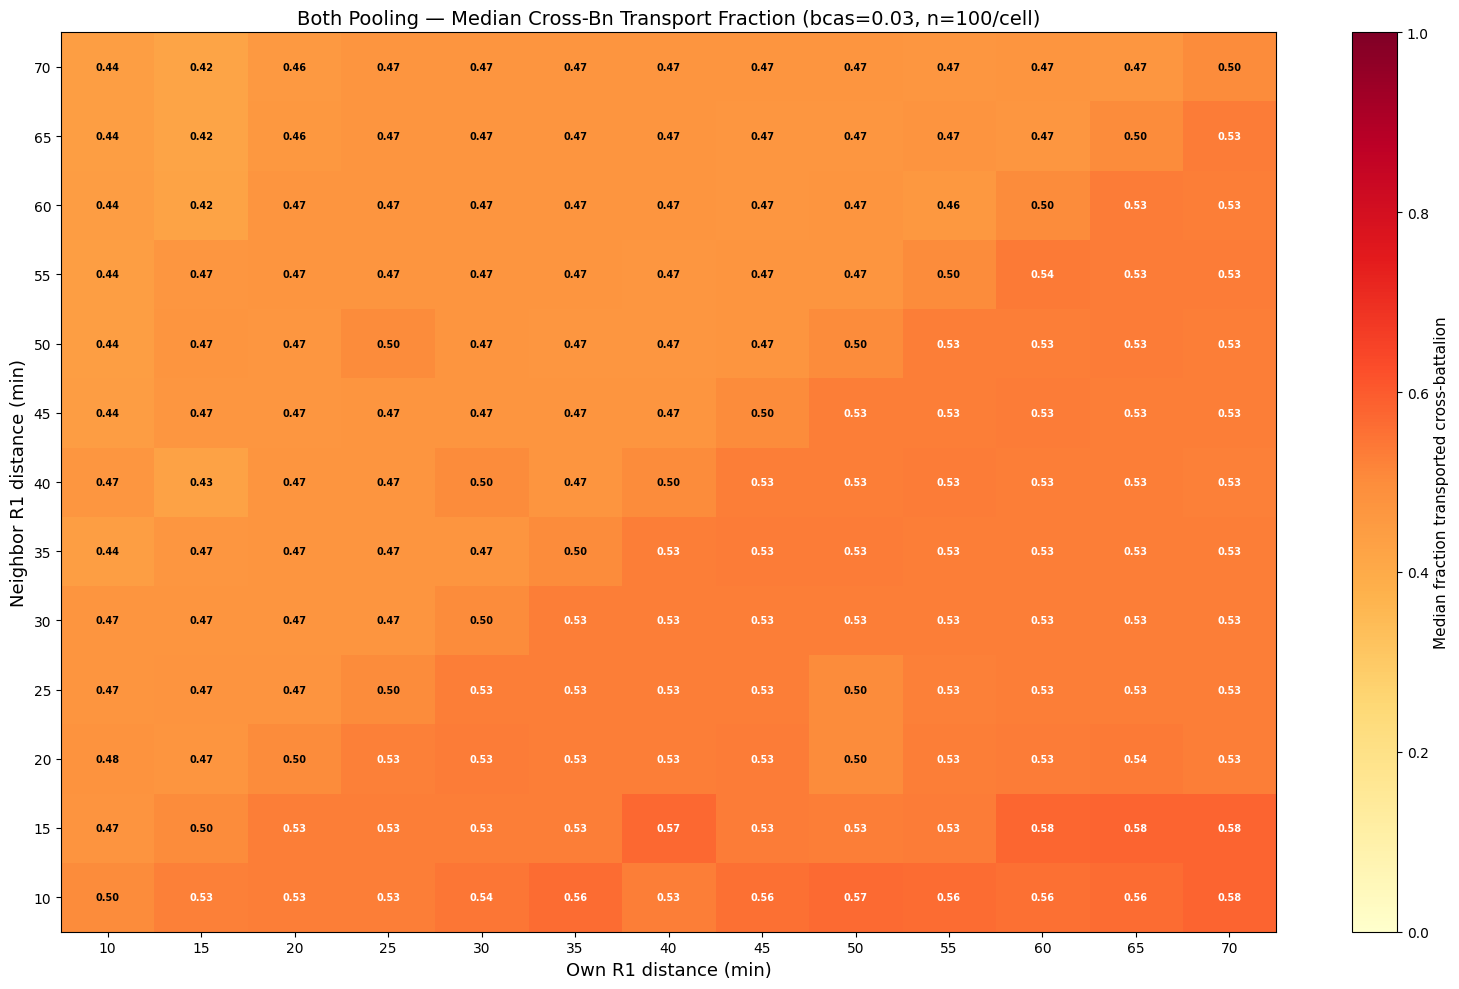

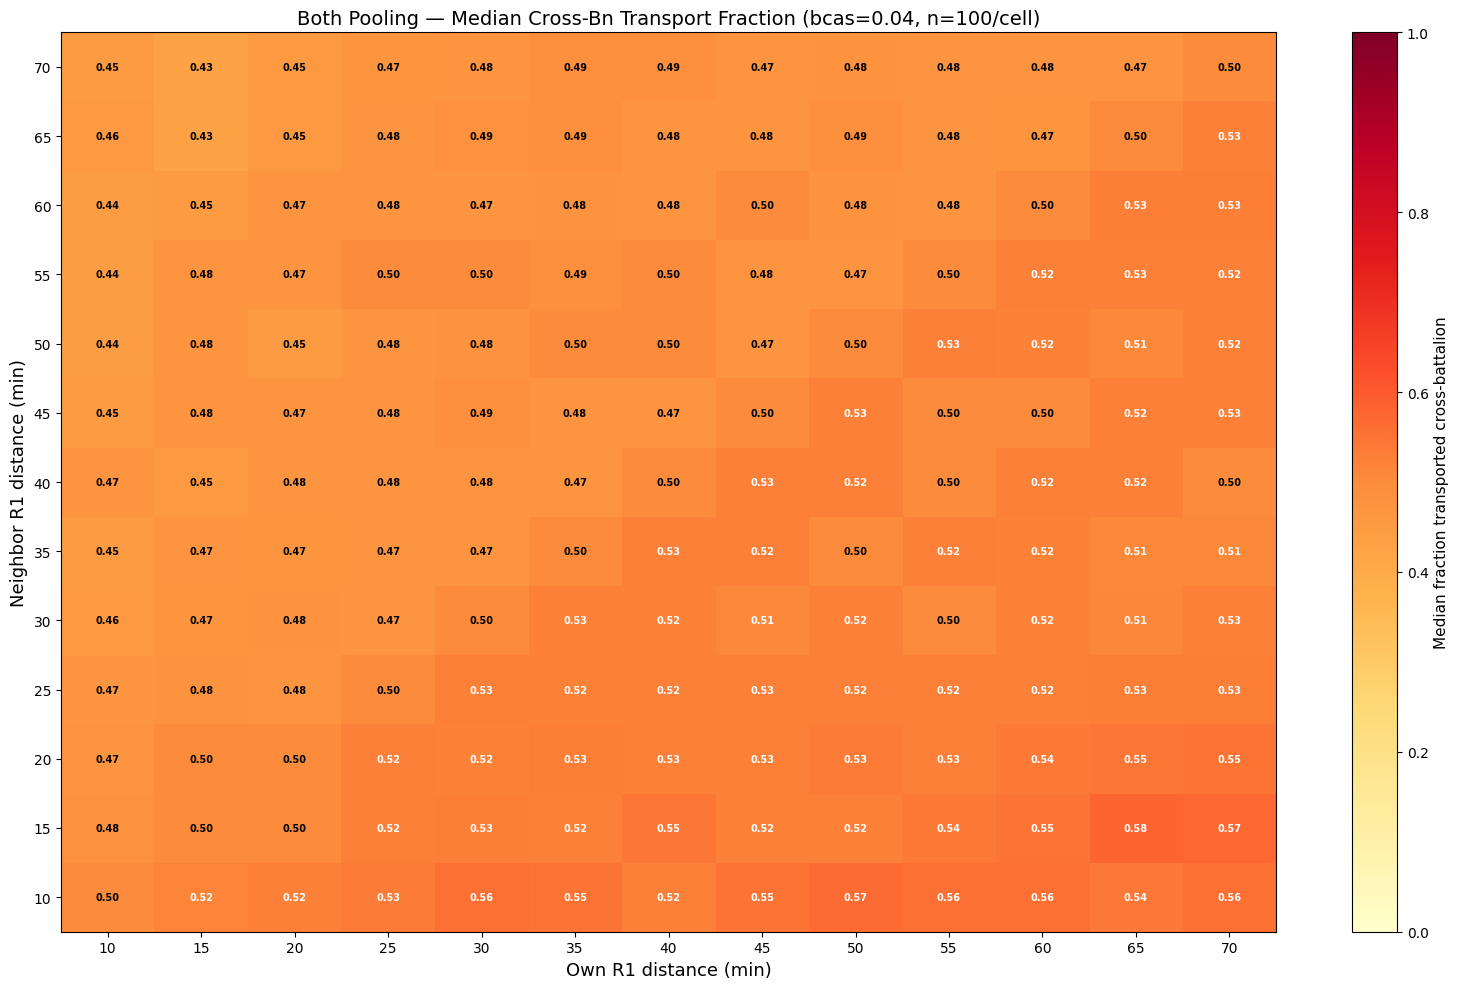

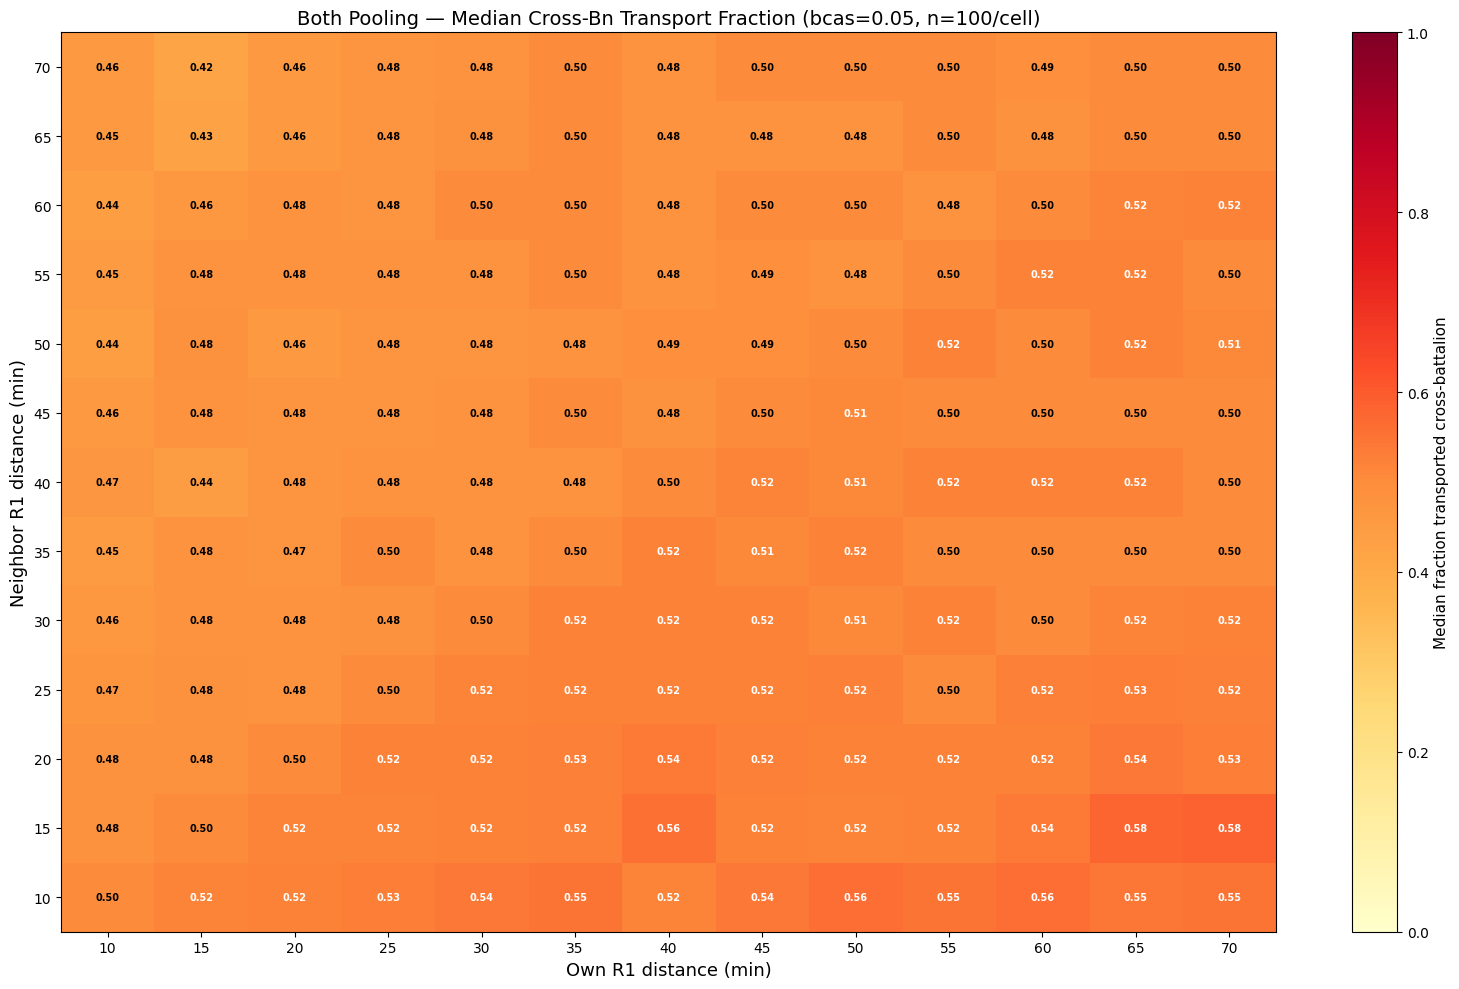

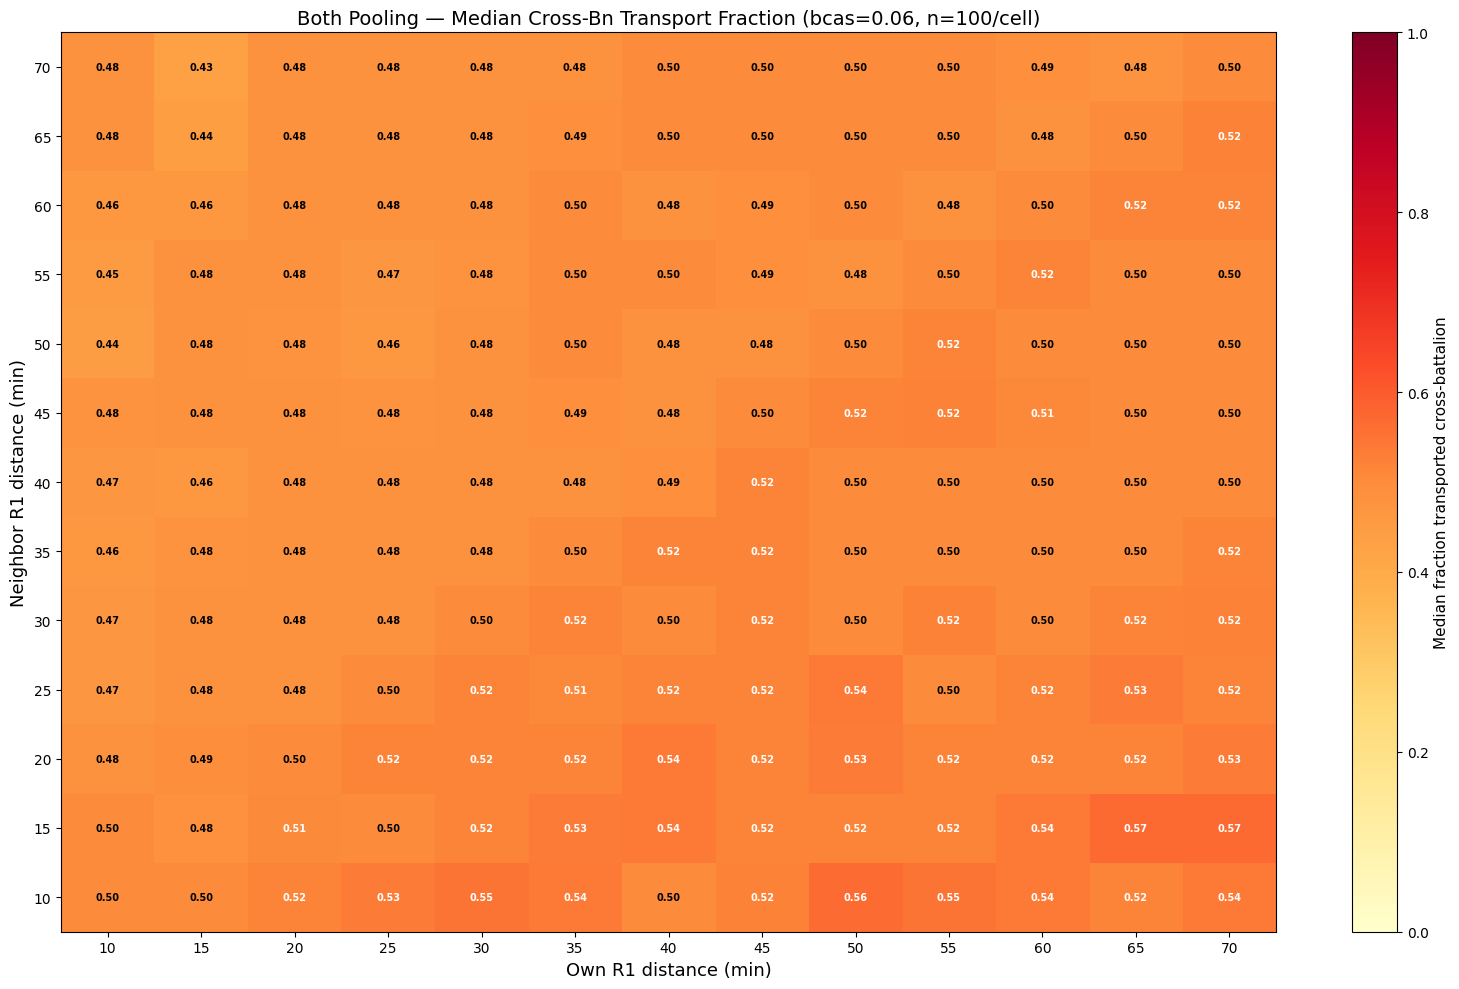

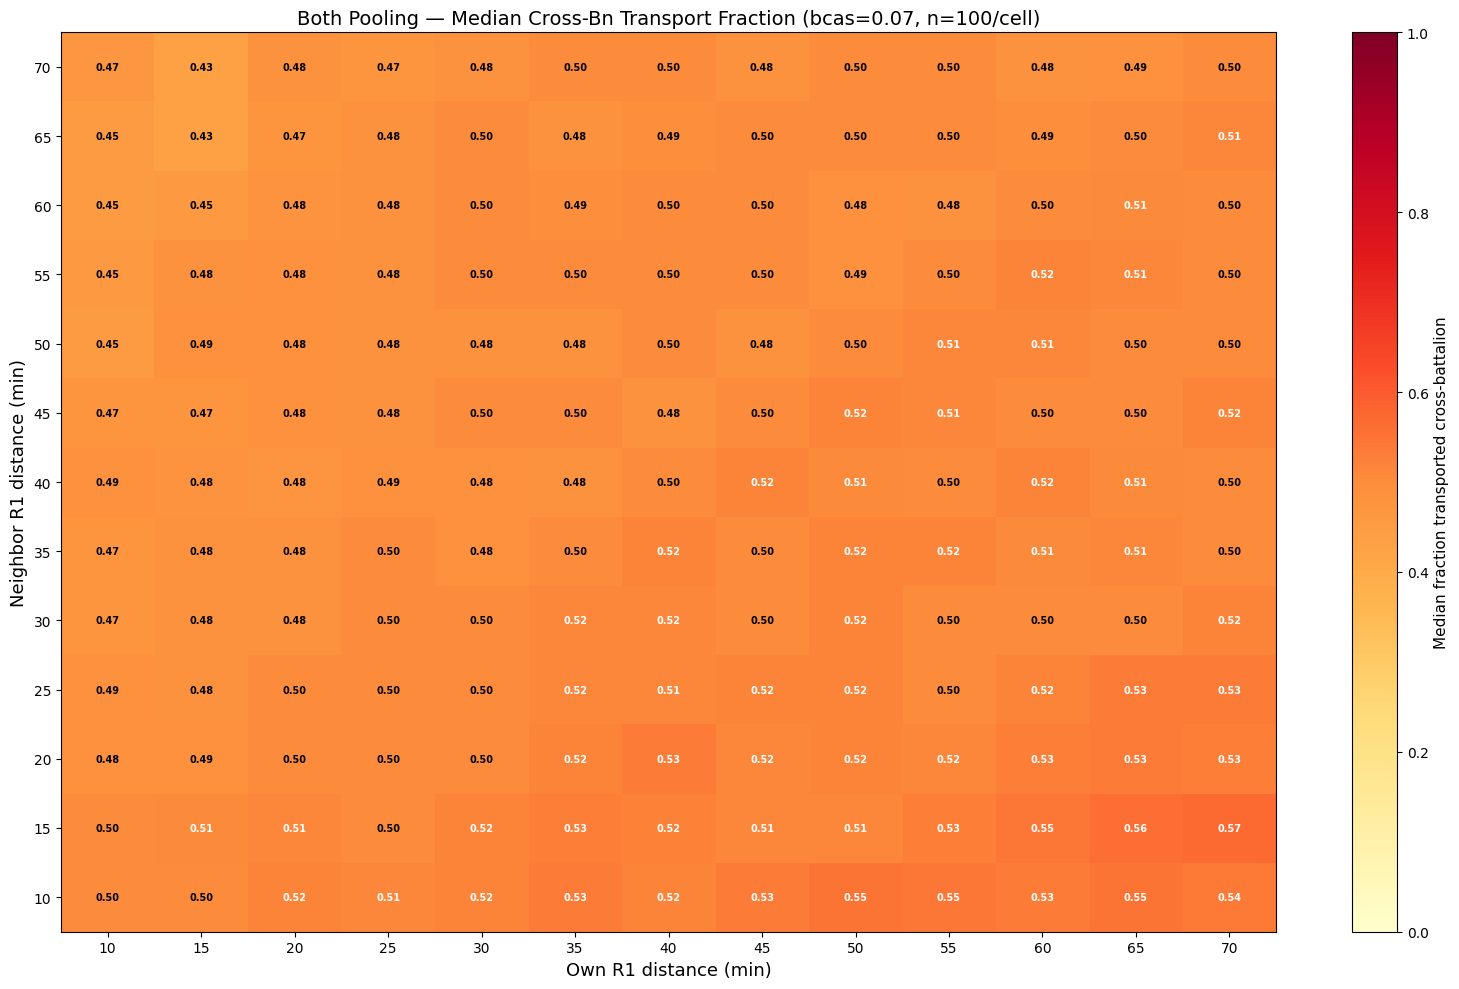

In [43]:
# Grid — pooling fraction (frac_transport_cross_bn) under both pooling per bcas
for bcas in sorted(df["bcas_rate"].unique()):
    sub = both[both["bcas_rate"] == bcas]
    grid = sub.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["frac_transport_cross_bn"].median().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_transport_cross_bn")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Both Pooling — Median Cross-Bn Transport Fraction (bcas={bcas}, n=100/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median fraction transported cross-battalion", fontsize=11)
    plt.tight_layout()
    plt.show()

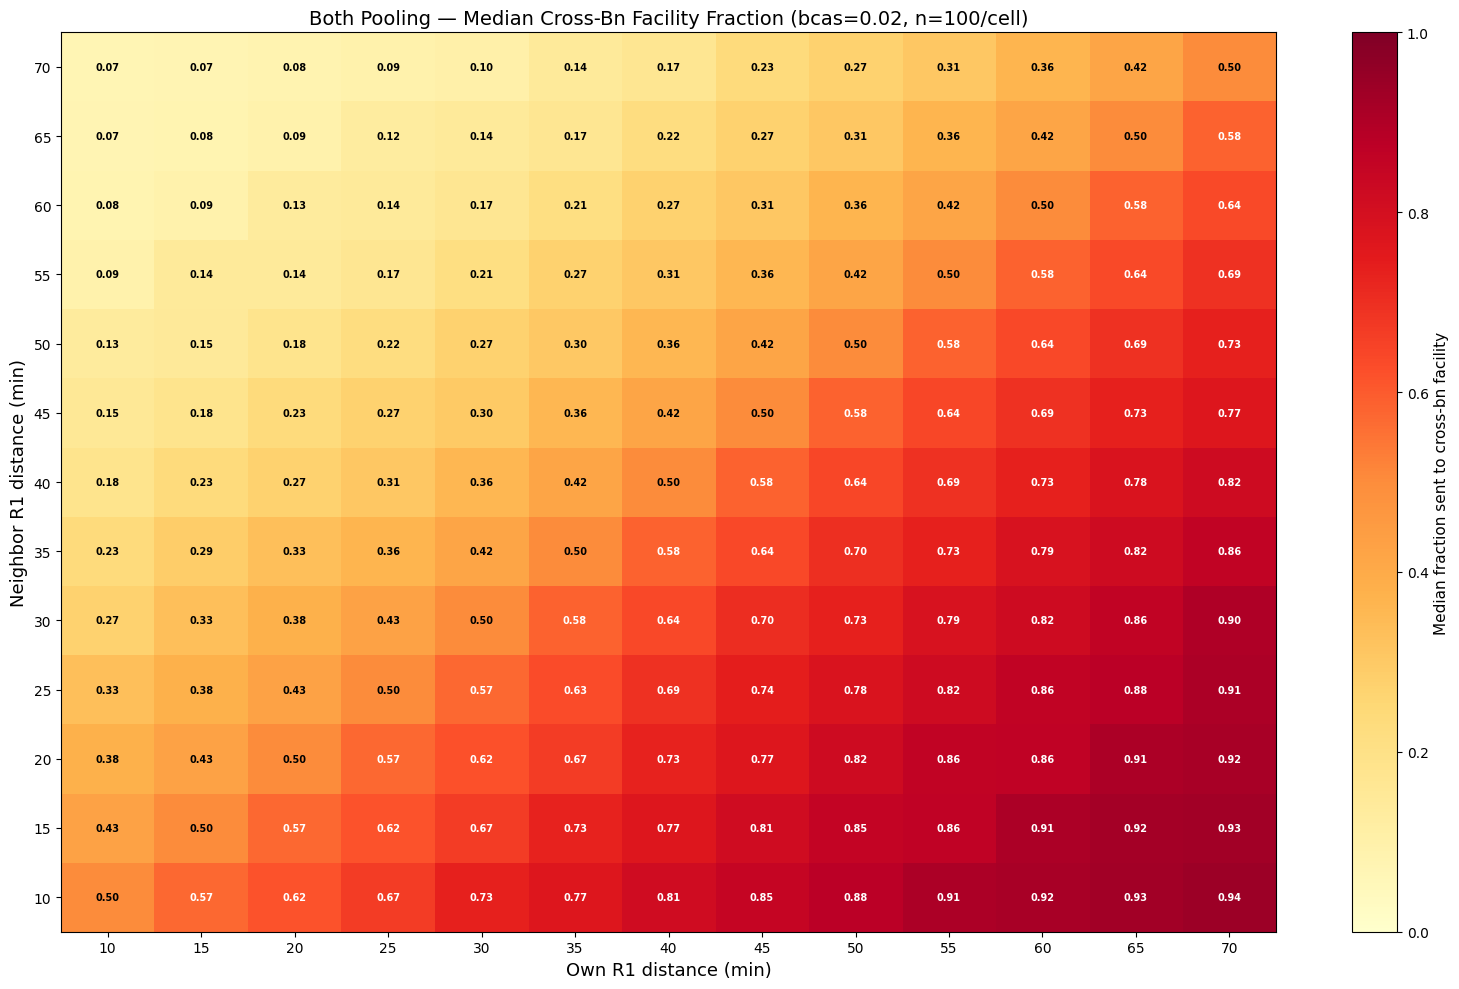

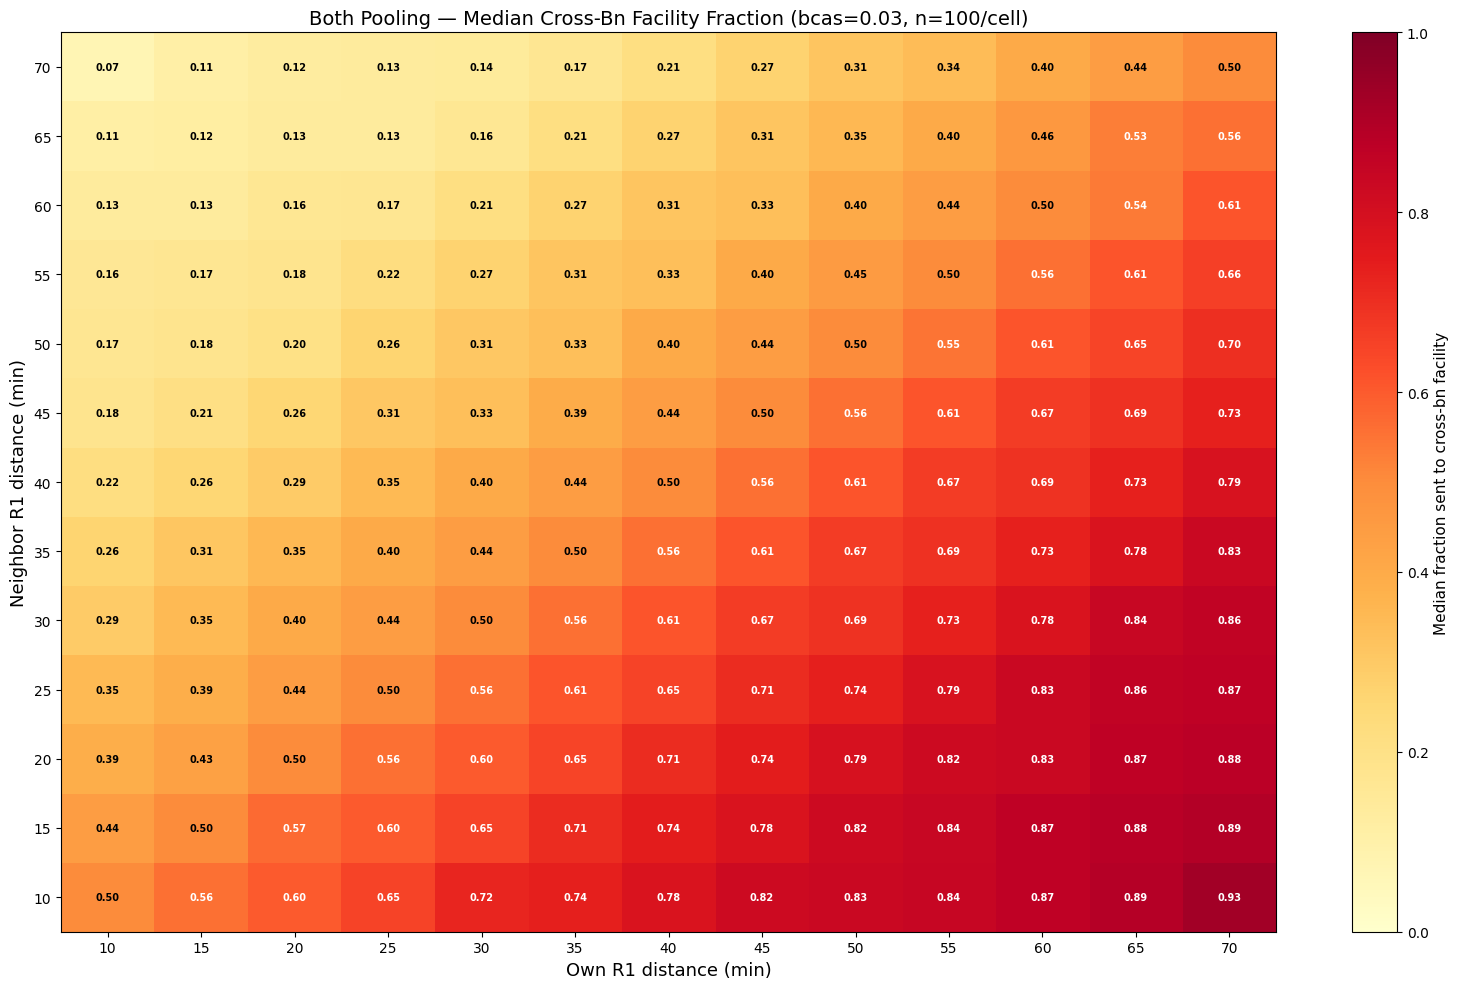

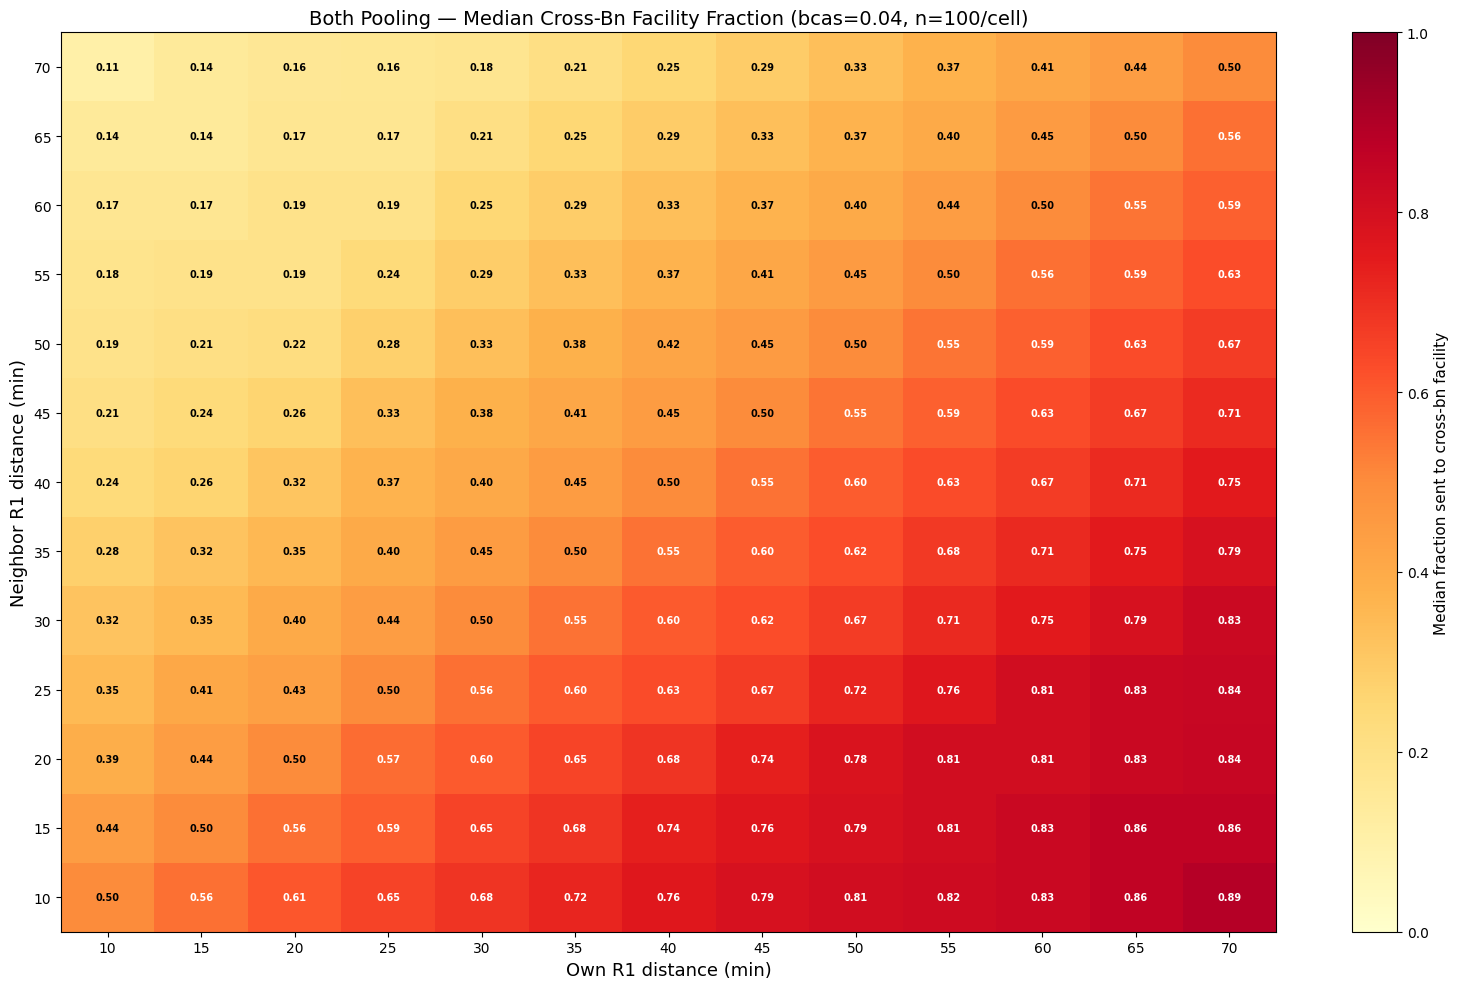

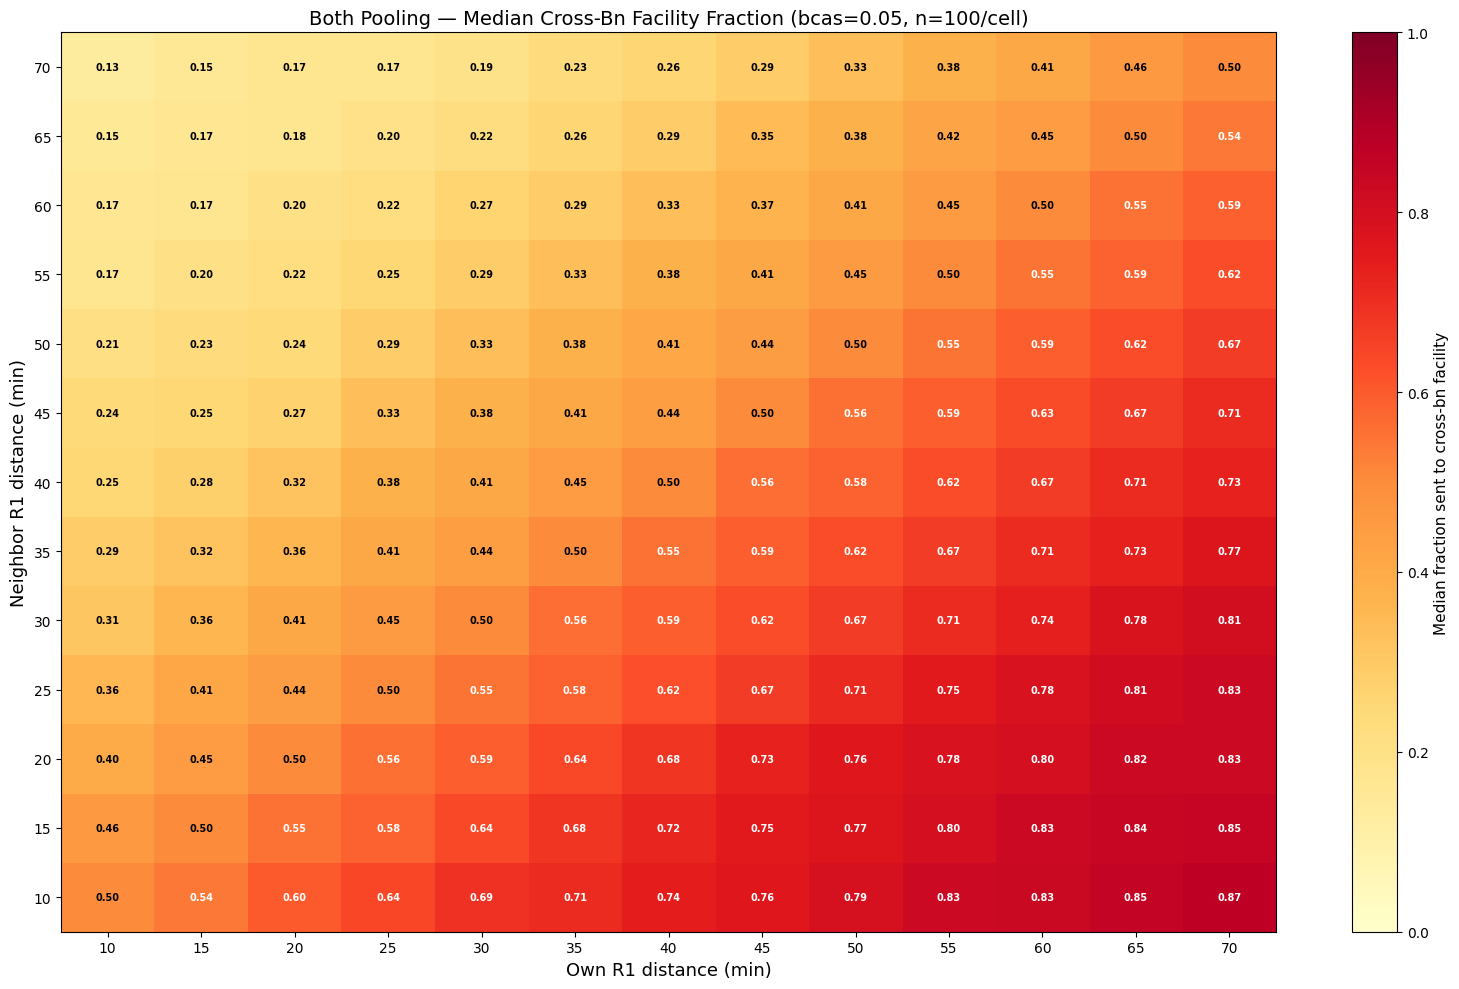

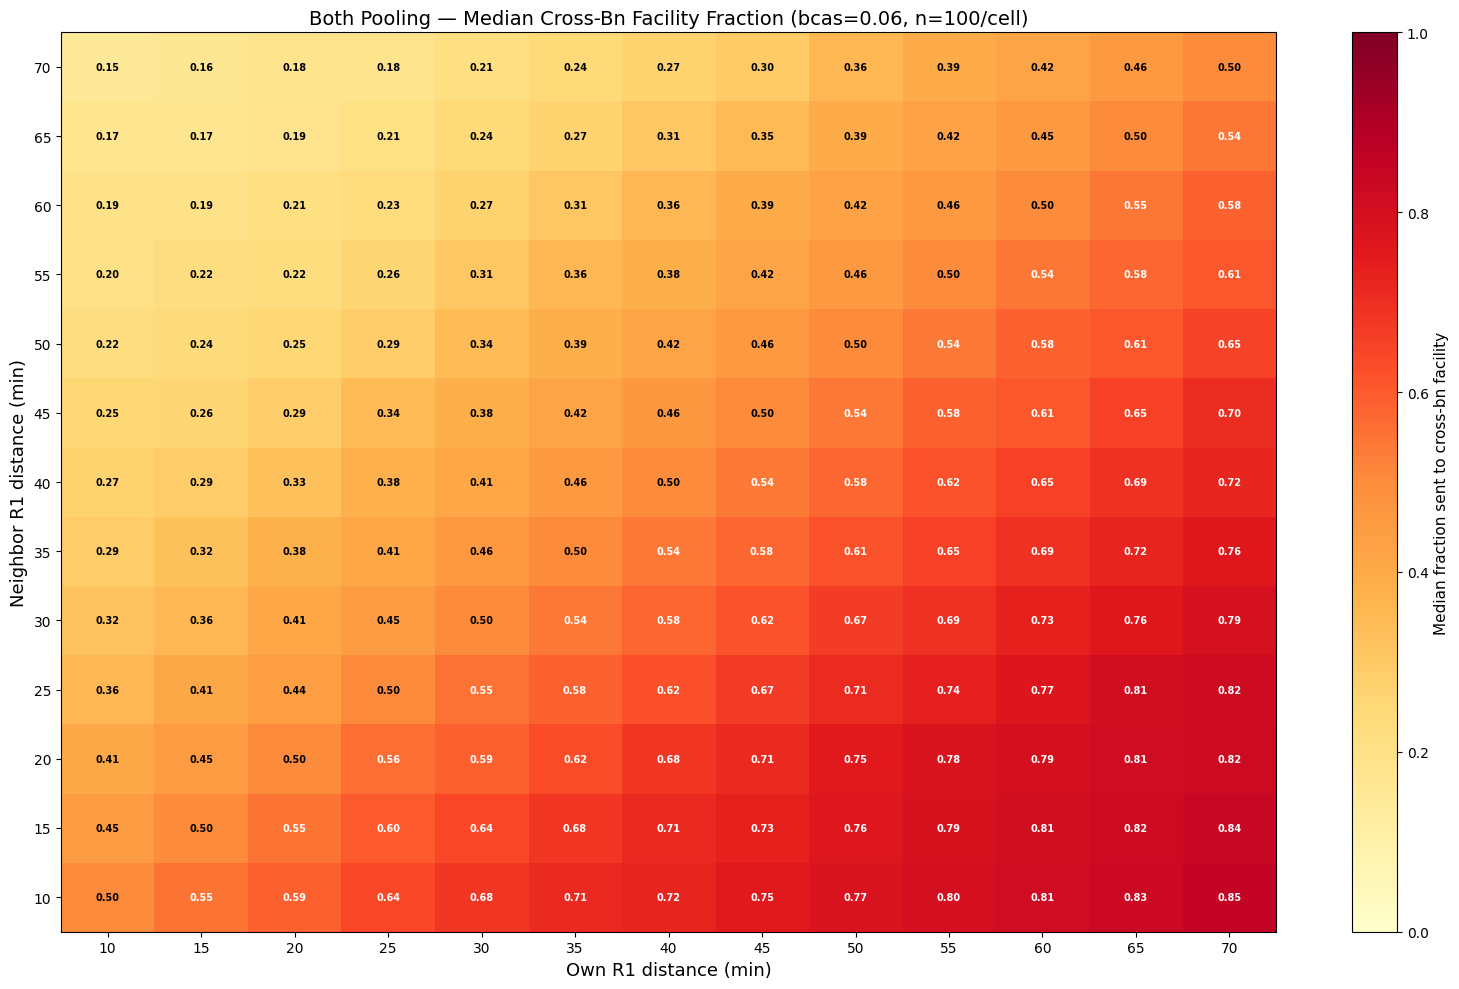

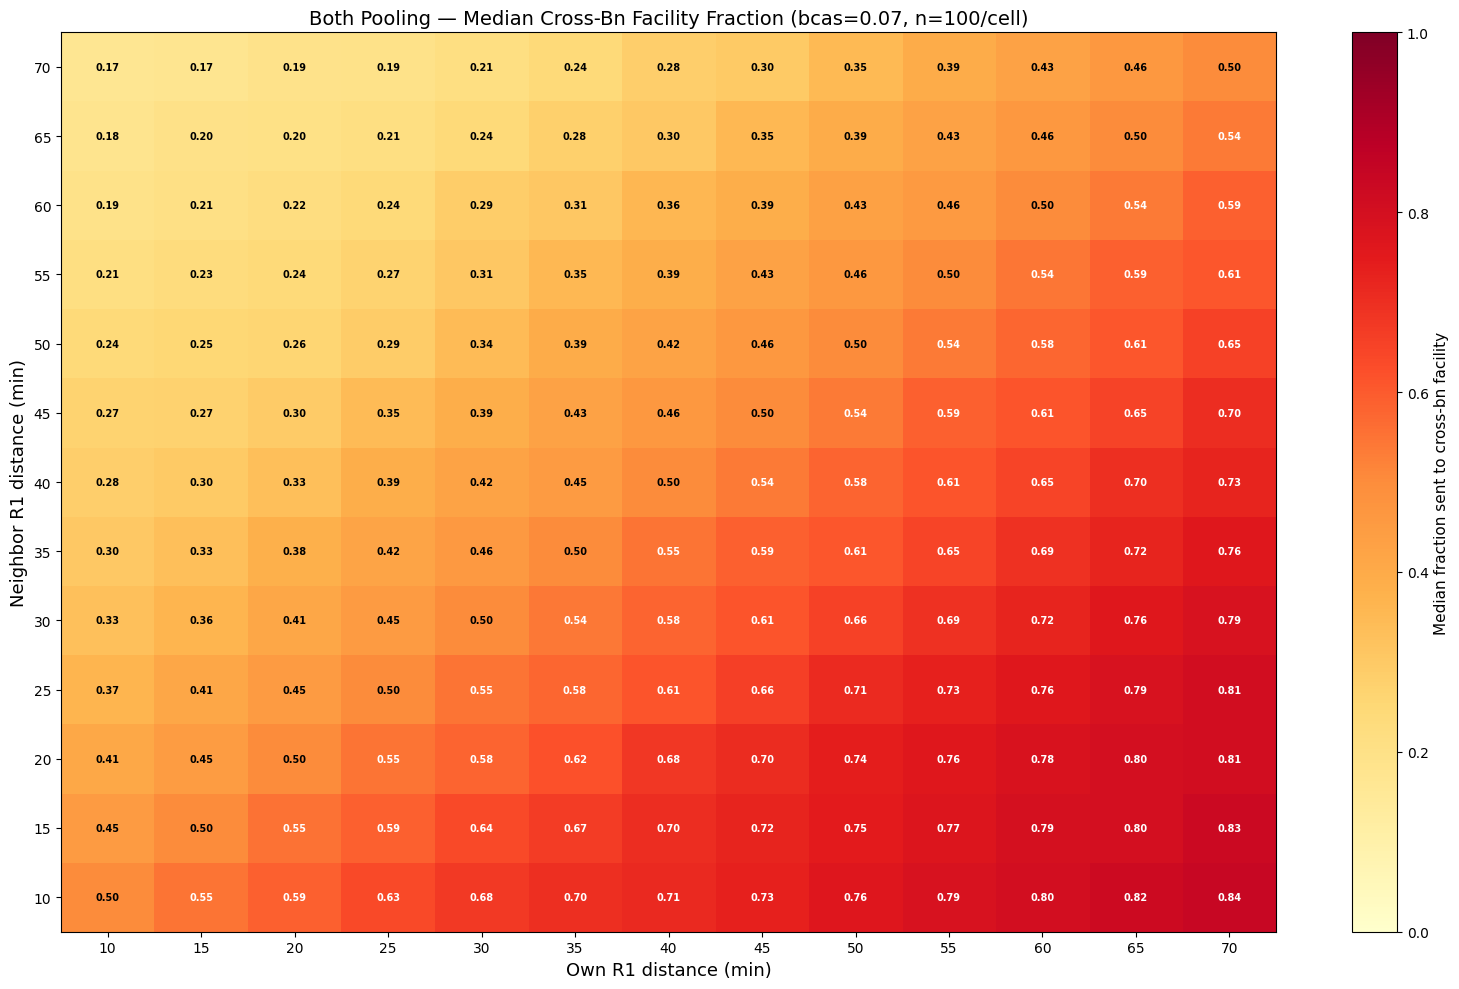

In [44]:
# Grid — facility cross-bn fraction (frac_facility_cross_bn) under both pooling per bcas
for bcas in sorted(df["bcas_rate"].unique()):
    sub = both[both["bcas_rate"] == bcas]
    grid = sub.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["frac_facility_cross_bn"].median().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_facility_cross_bn")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Both Pooling — Median Cross-Bn Facility Fraction (bcas={bcas}, n=100/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median fraction sent to cross-bn facility", fontsize=11)
    plt.tight_layout()
    plt.show()

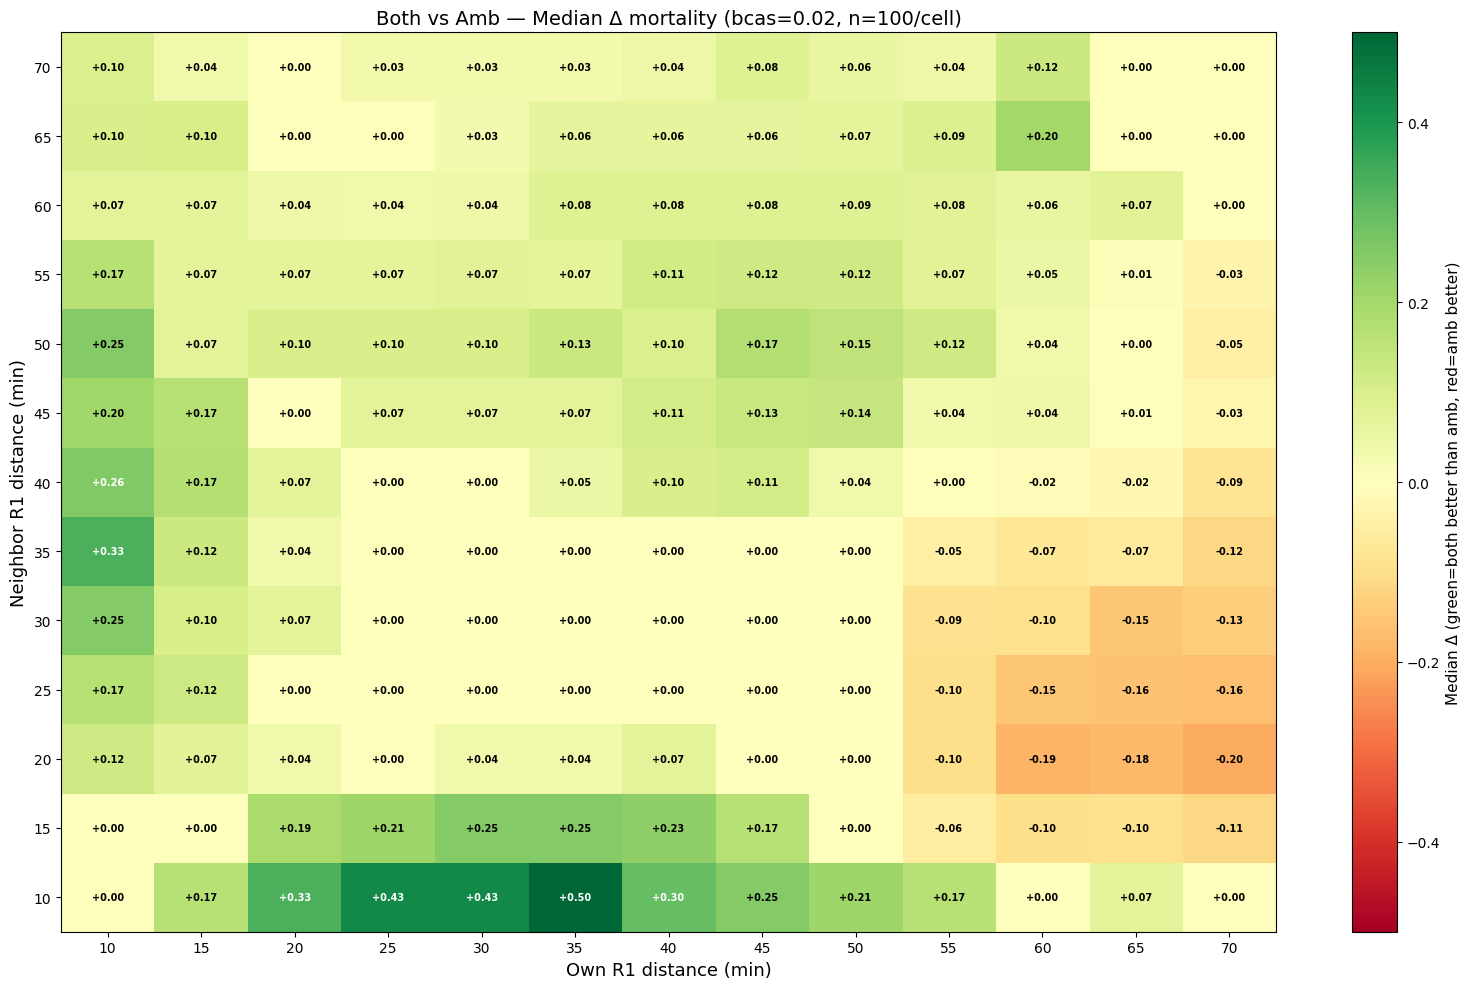

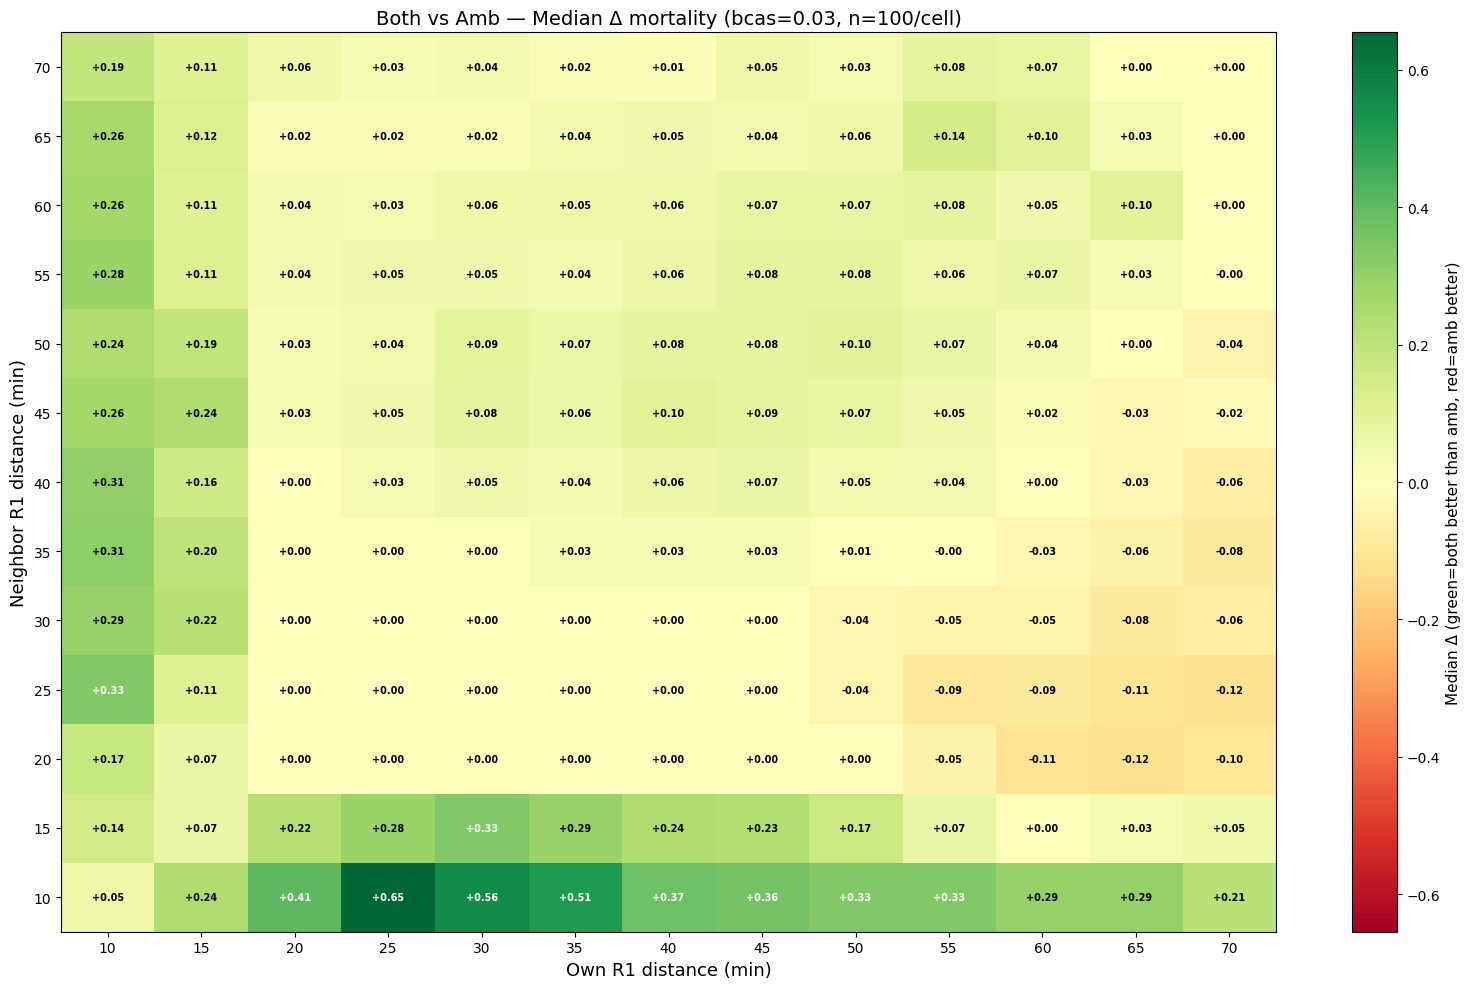

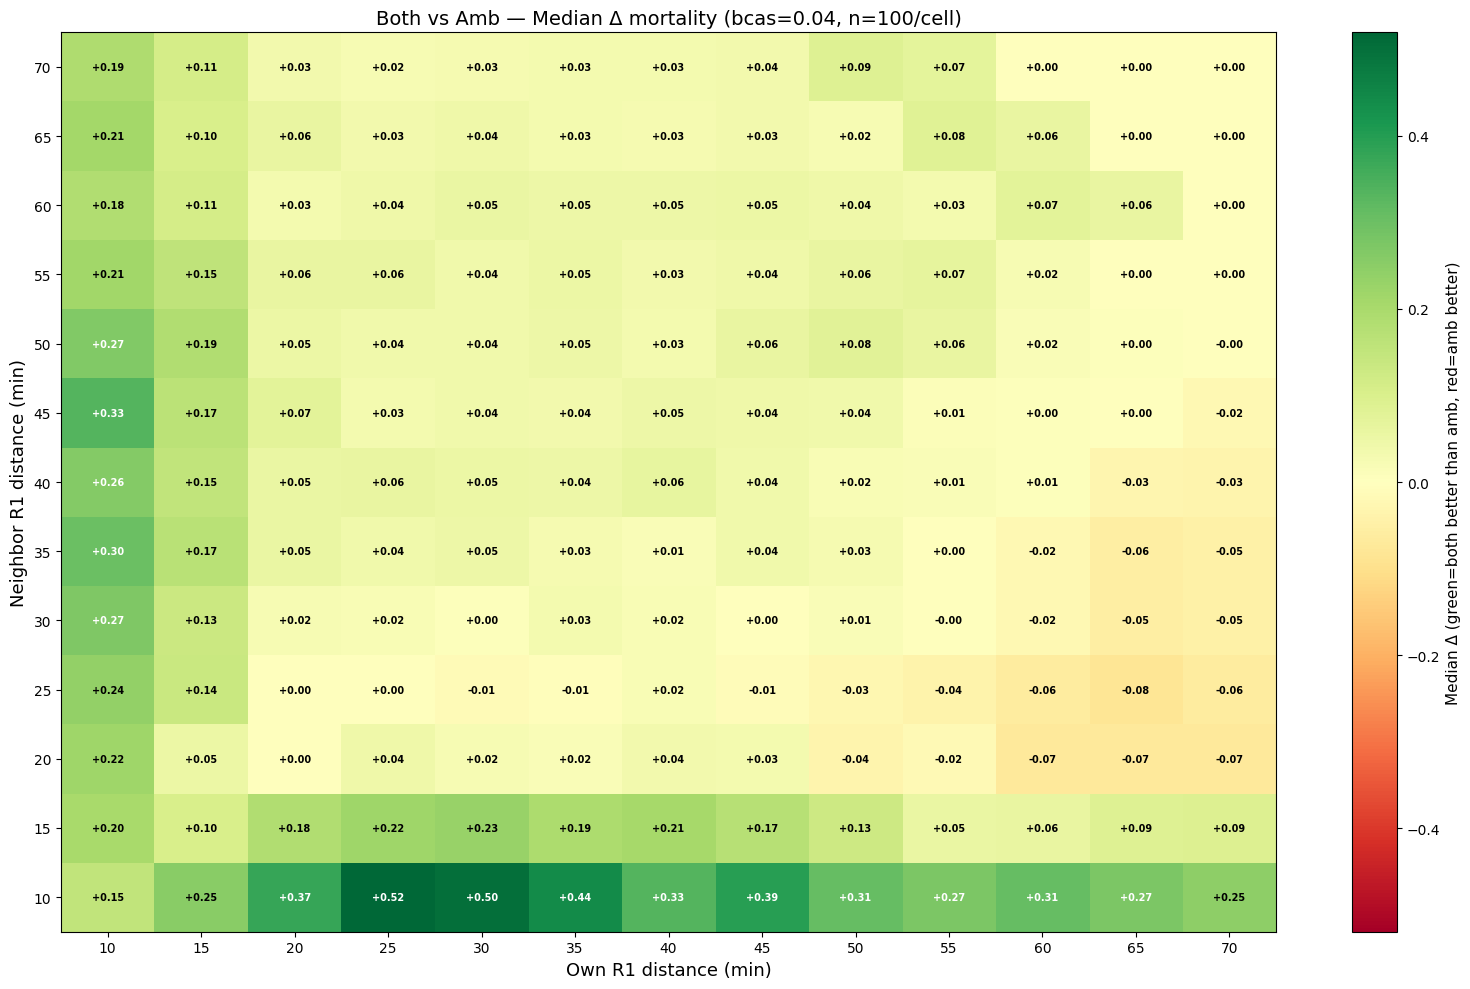

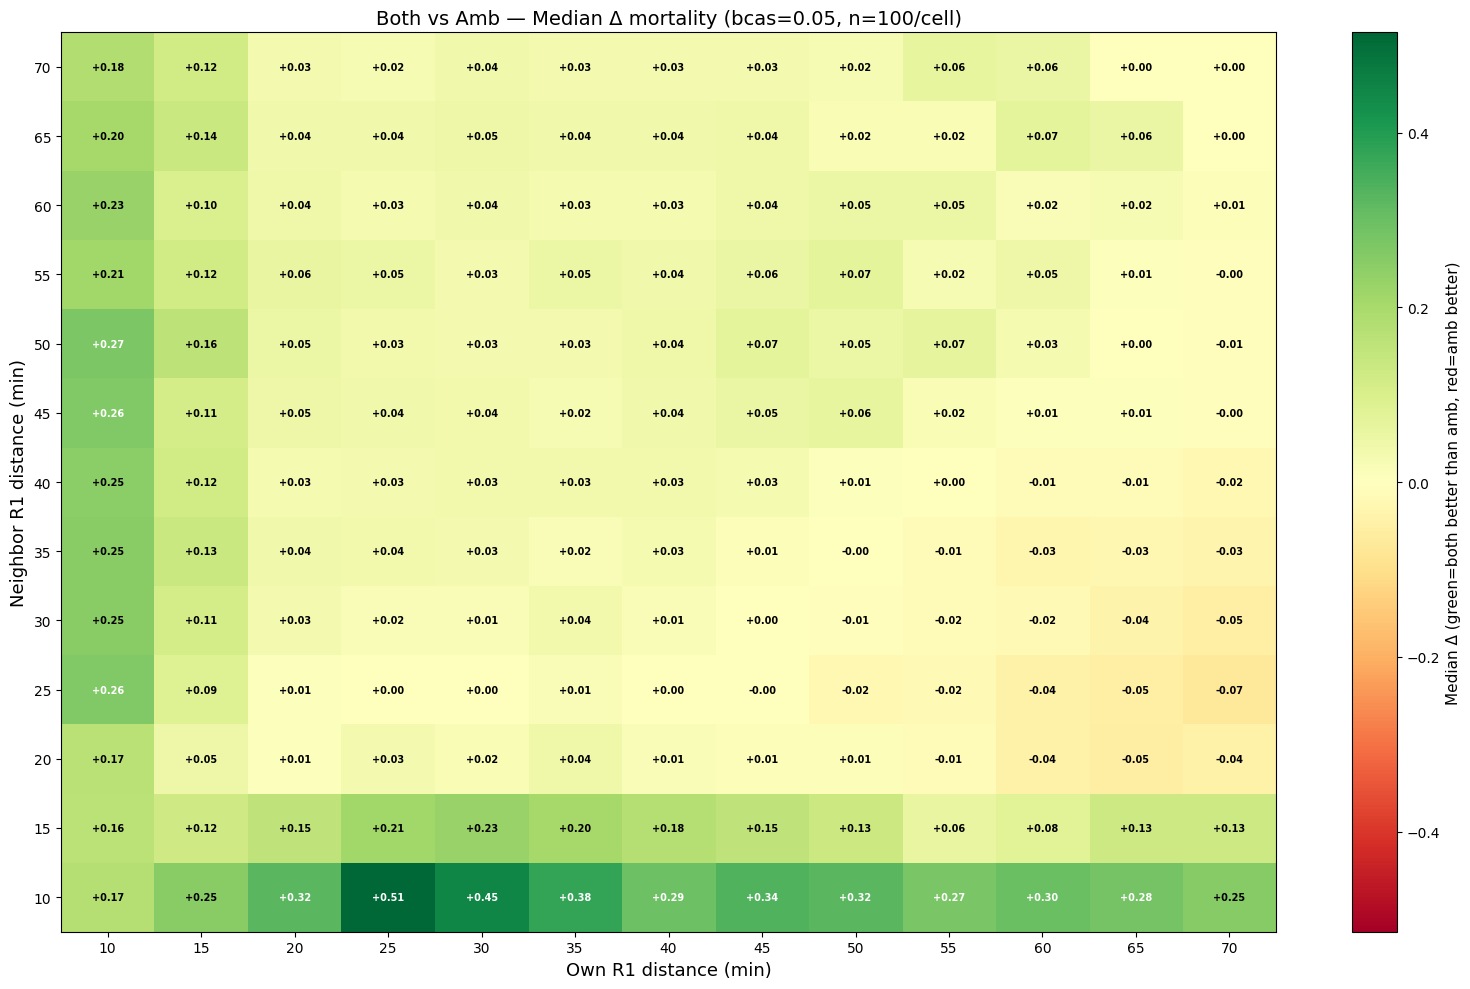

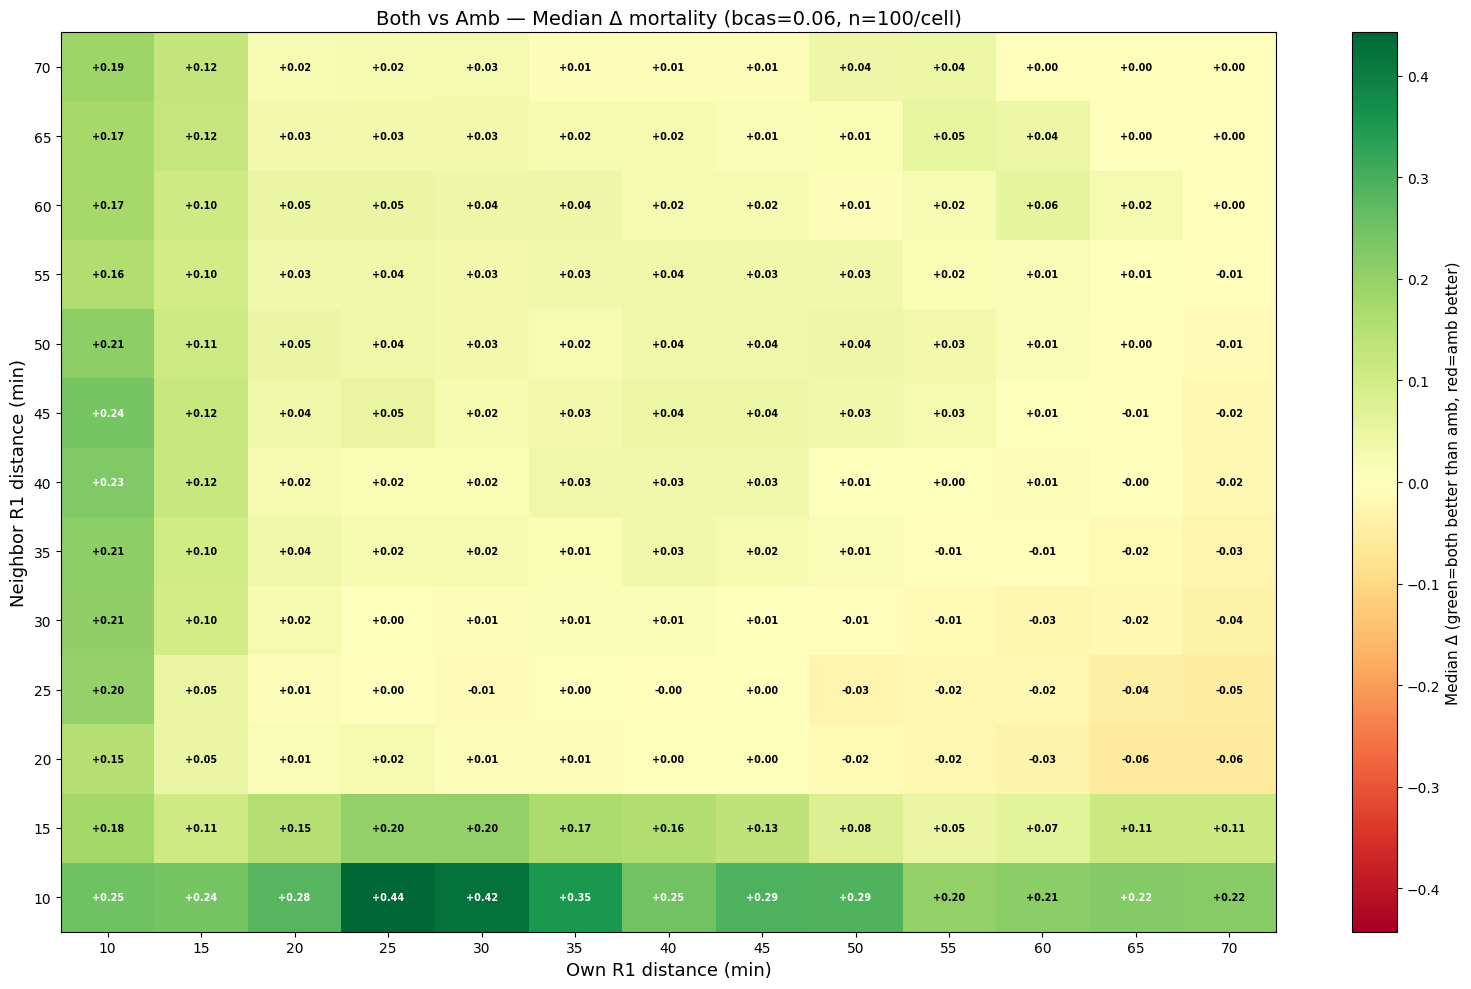

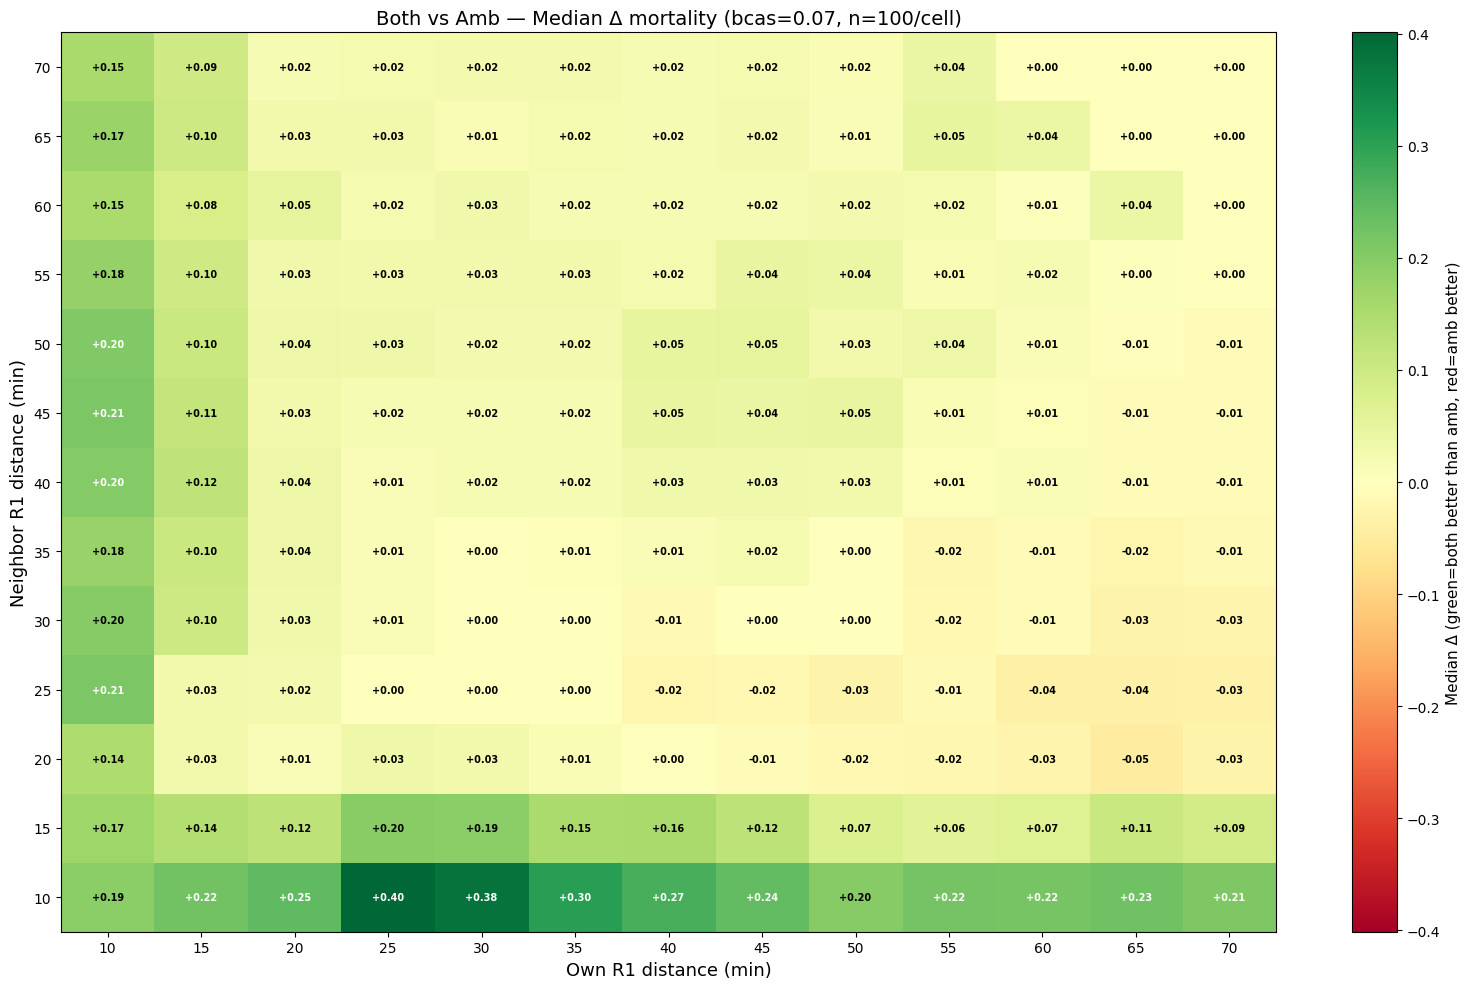

In [45]:
# Grid — delta both vs amb (what does adding facility pooling on top of amb pooling buy?)
for bcas in sorted(df["bcas_rate"].unique()):
    a = amb[amb["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    b = both[both["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    delta = (a - b).reset_index()
    delta.columns = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "delta"]
    pivot = delta.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="delta")

    vmax = max(abs(pivot.values.min()), abs(pivot.values.max()), 0.01)

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="RdYlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=-vmax, vmax=vmax)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Both vs Amb — Median Δ mortality (bcas={bcas}, n=100/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if abs(val) > vmax * 0.5 else "black"
            ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median Δ (green=both better than amb, red=amb better)", fontsize=11)
    plt.tight_layout()
    plt.show()

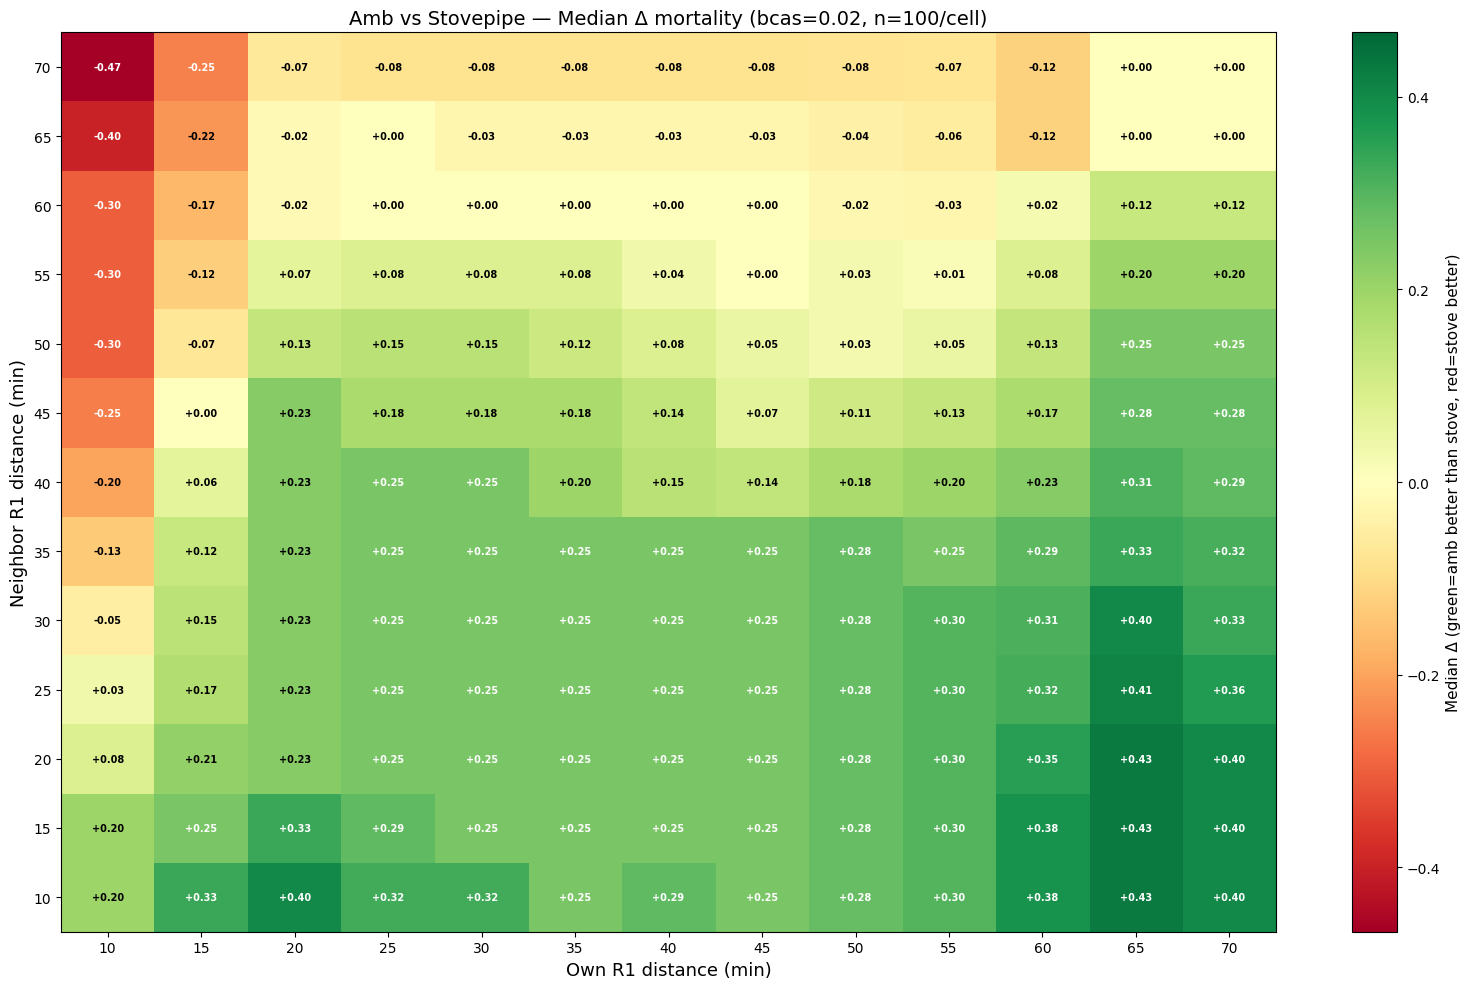

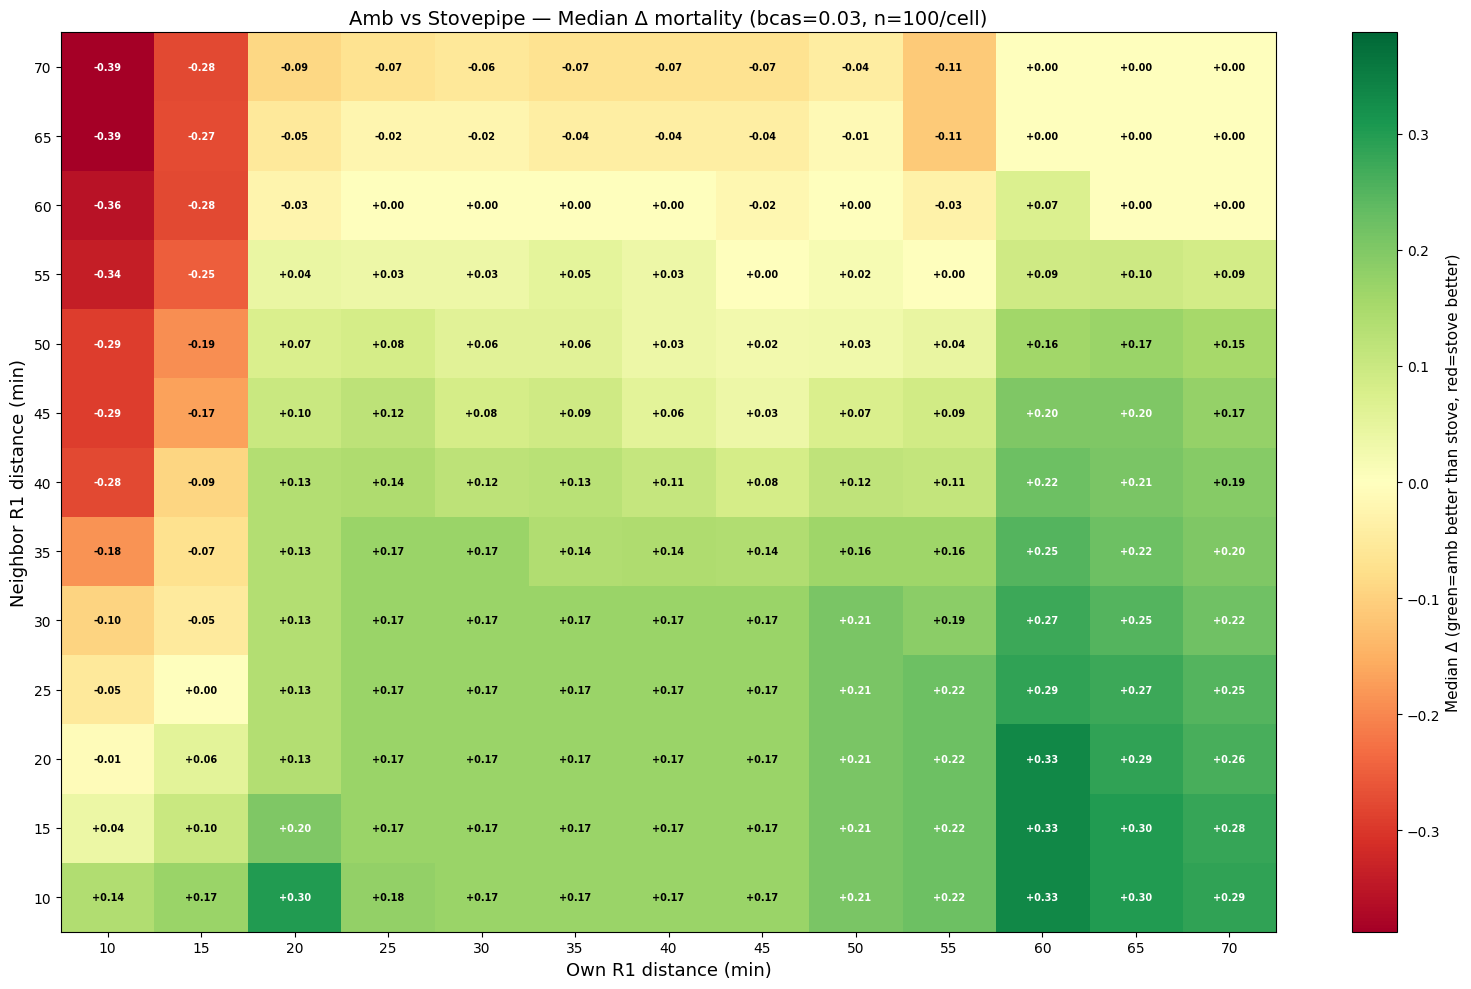

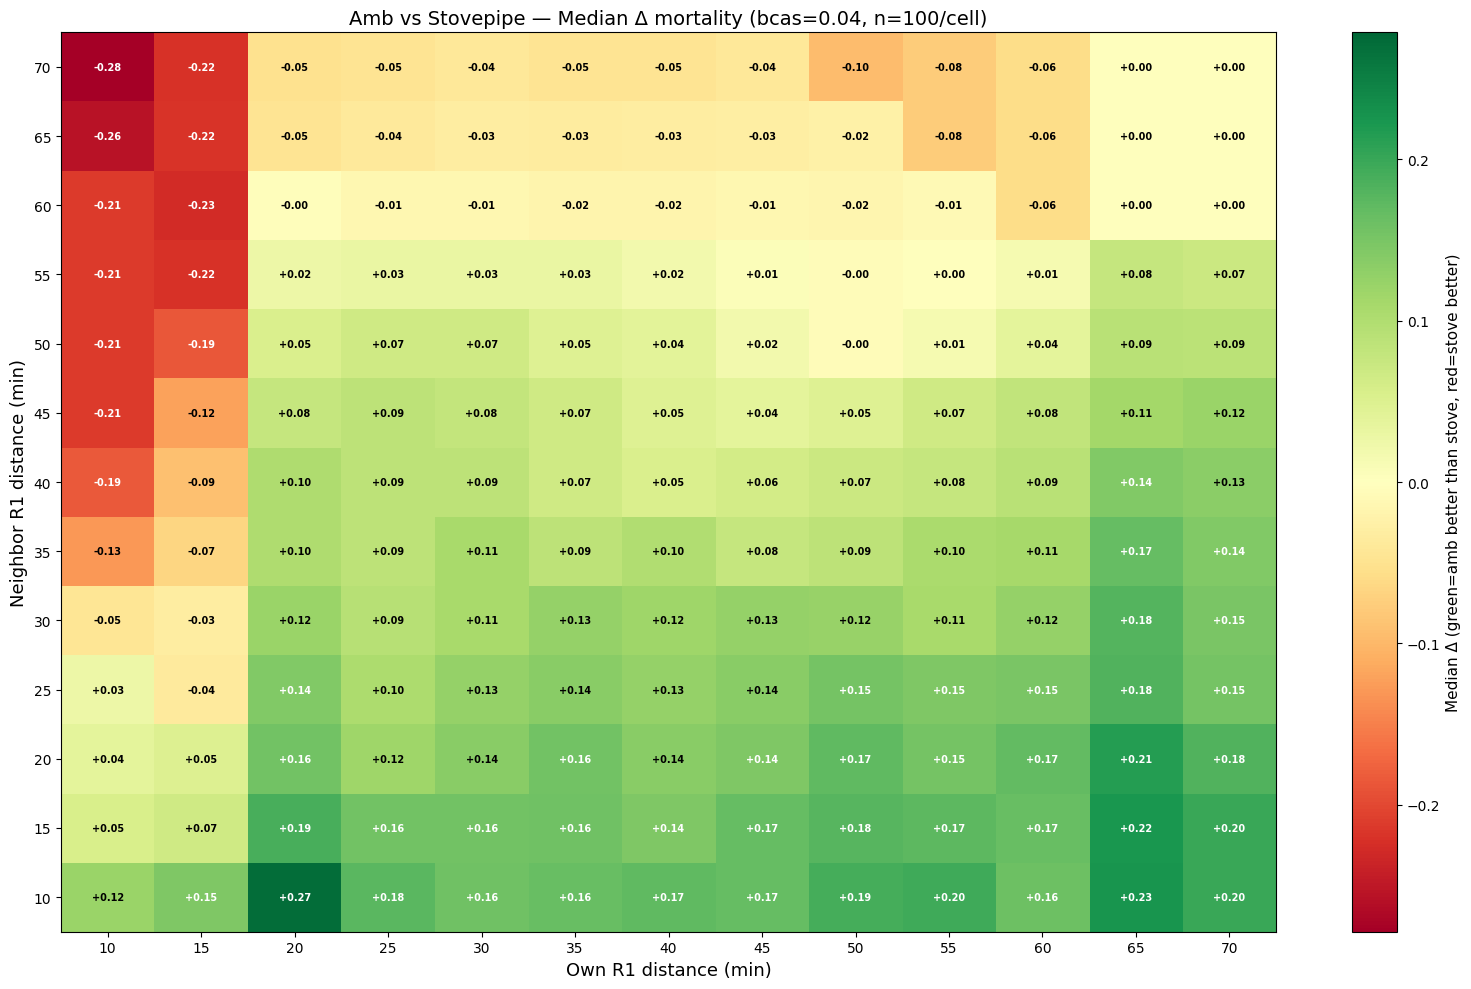

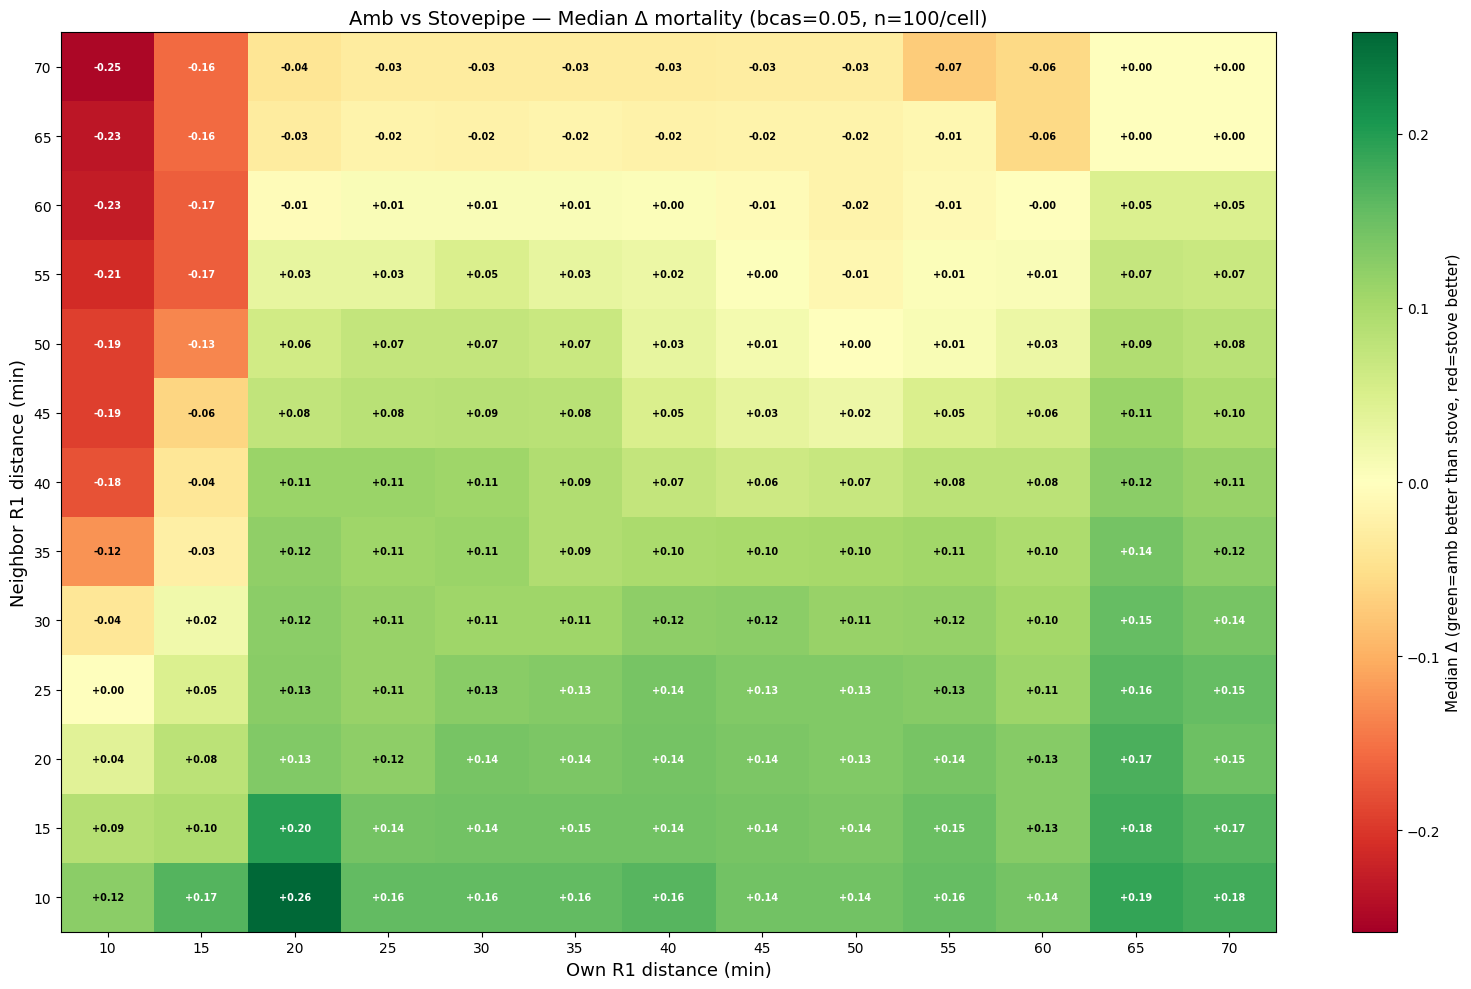

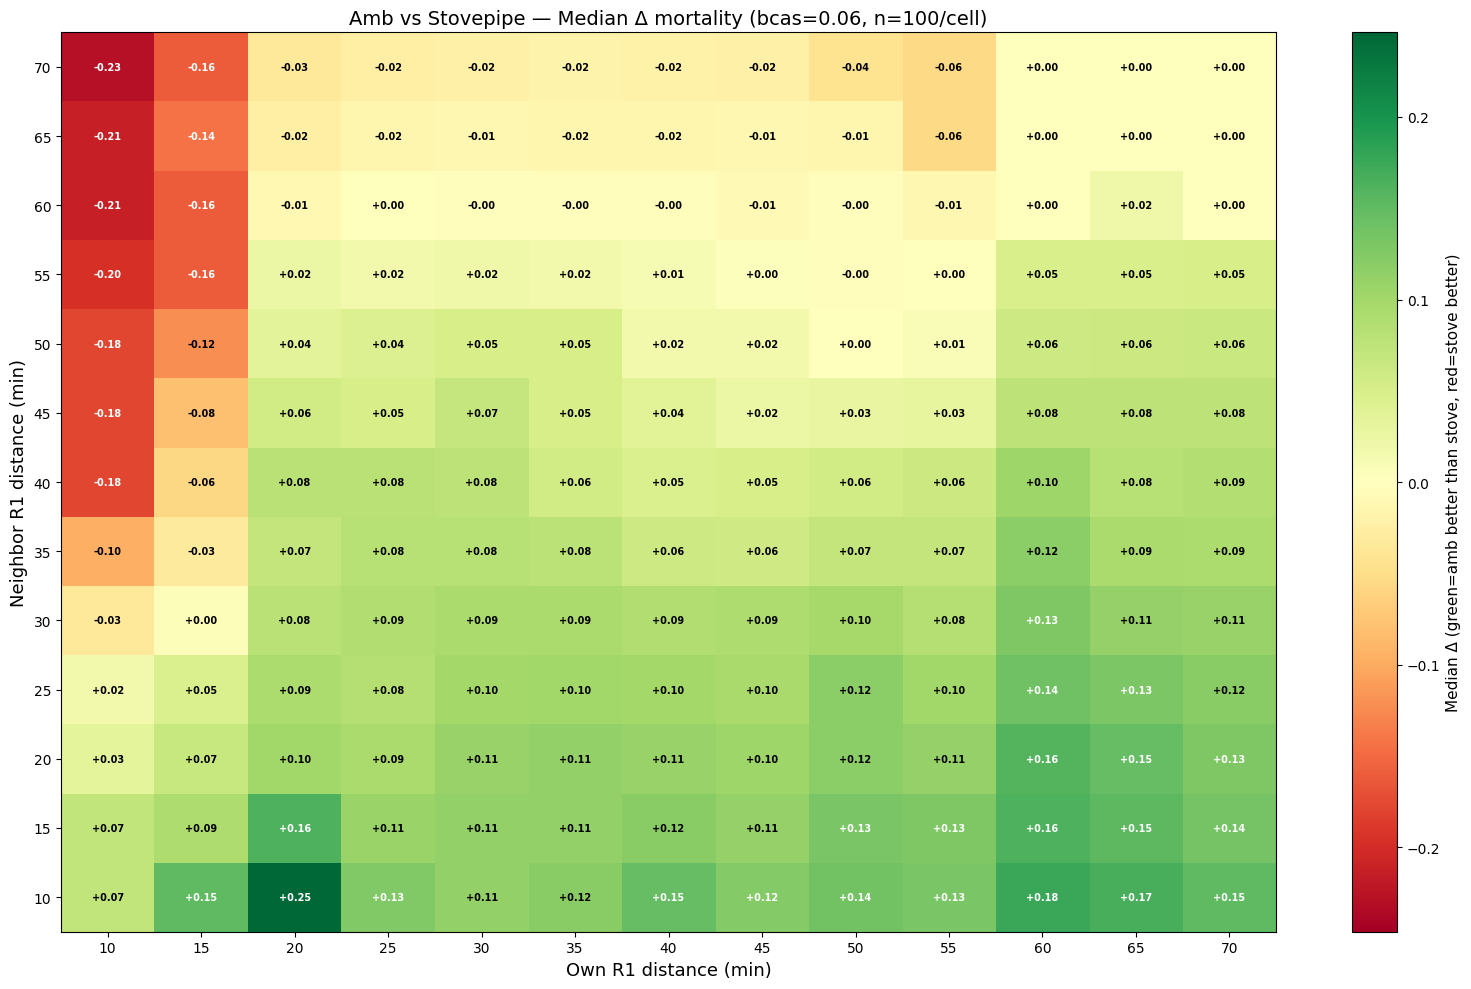

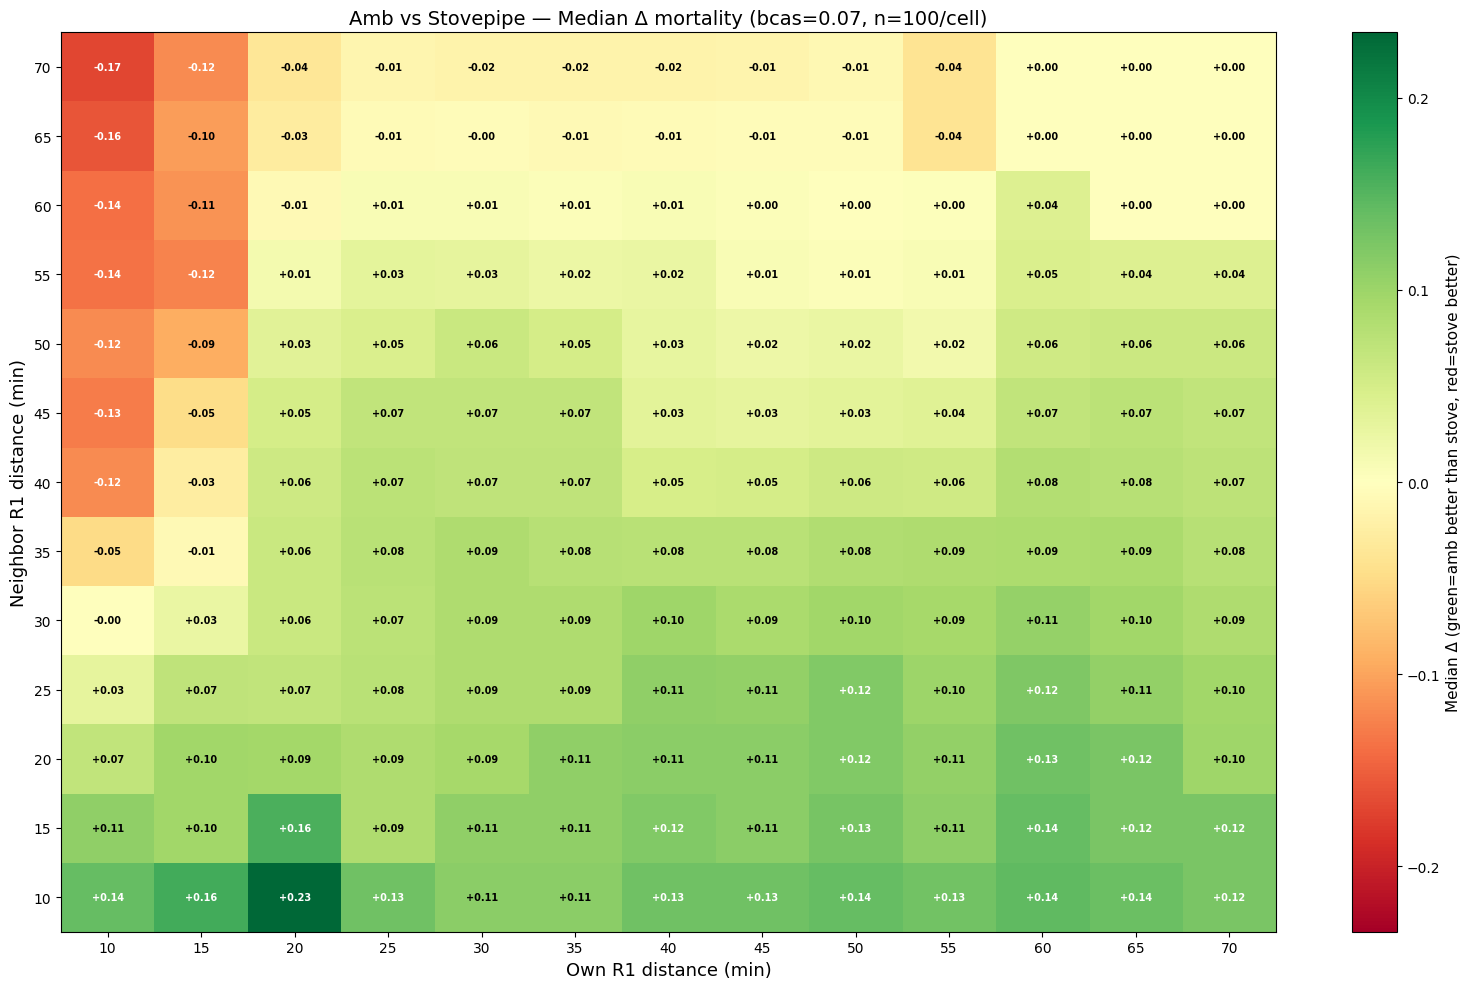

In [46]:
# Grid — delta amb vs stovepipe (what does ambulance pooling alone buy?)
for bcas in sorted(df["bcas_rate"].unique()):
    s = stove[stove["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    a = amb[amb["bcas_rate"] == bcas].groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["death_rate_T1_BCAS"].median()
    delta = (s - a).reset_index()
    delta.columns = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "delta"]
    pivot = delta.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="delta")

    vmax = max(abs(pivot.values.min()), abs(pivot.values.max()), 0.01)

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="RdYlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=-vmax, vmax=vmax)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Amb vs Stovepipe — Median Δ mortality (bcas={bcas}, n=100/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if abs(val) > vmax * 0.5 else "black"
            ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median Δ (green=amb better than stove, red=stove better)", fontsize=11)
    plt.tight_layout()
    plt.show()

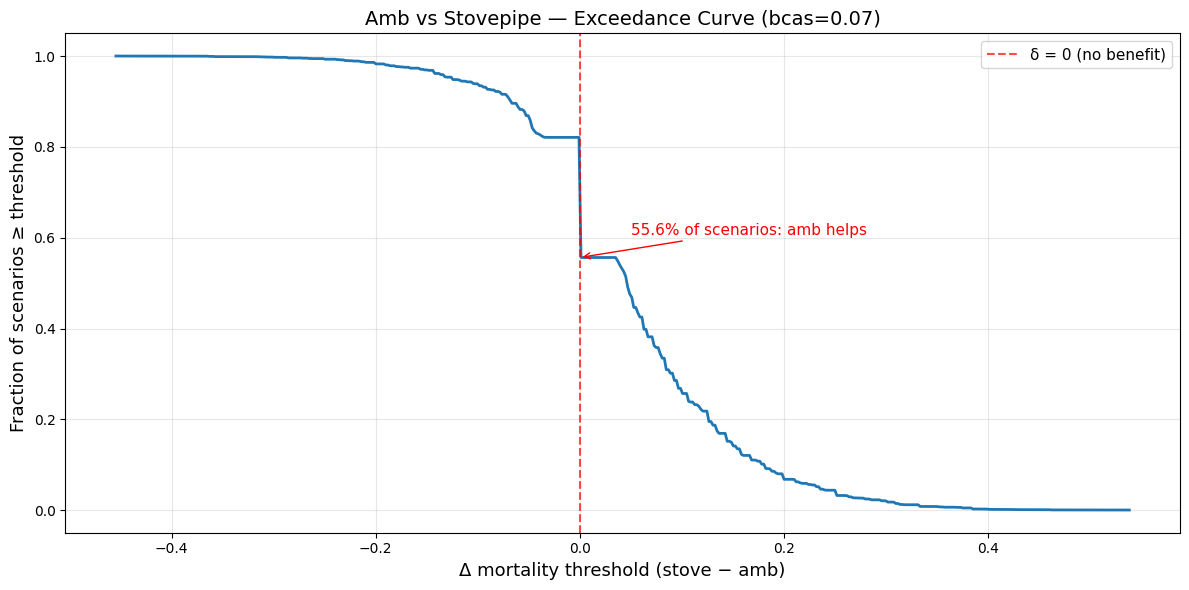

bcas=0.07: 16900 scenario pairs
  Amb helps (δ>0): 55.6%
  Amb hurts (δ<0): 17.9%
  Median δ: +0.0455
  Mean δ:   +0.0482


In [47]:
# Exceedance curve — fraction of scenarios where amb pooling benefit (stove - amb) exceeds threshold
BCAS = 0.07
# <-- change this

MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
s = stove[stove["bcas_rate"] == BCAS].sort_values(MATCH_COLS).reset_index(drop=True)
a = amb[amb["bcas_rate"] == BCAS].sort_values(MATCH_COLS).reset_index(drop=True)
assert (s[MATCH_COLS].values == a[MATCH_COLS].values).all()

delta = s["death_rate_T1_BCAS"].values - a["death_rate_T1_BCAS"].values

thresholds = np.linspace(delta.min(), delta.max(), 500)
exceedance = [(delta >= t).mean() for t in thresholds]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(thresholds, exceedance, linewidth=2)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="δ = 0 (no benefit)")
ax.set_xlabel("Δ mortality threshold (stove − amb)", fontsize=13)
ax.set_ylabel("Fraction of scenarios ≥ threshold", fontsize=13)
ax.set_title(f"Amb vs Stovepipe — Exceedance Curve (bcas={BCAS})", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

pct_positive = (delta > 0).mean()
ax.annotate(f"{pct_positive:.1%} of scenarios: amb helps",
            xy=(0, pct_positive), xytext=(0.05, pct_positive + 0.05),
            fontsize=11, arrowprops=dict(arrowstyle="->", color="red"), color="red")
plt.tight_layout()
plt.show()

print(f"bcas={BCAS}: {len(delta)} scenario pairs")
print(f"  Amb helps (δ>0): {(delta>0).mean():.1%}")
print(f"  Amb hurts (δ<0): {(delta<0).mean():.1%}")
print(f"  Median δ: {np.median(delta):+.4f}")
print(f"  Mean δ:   {np.mean(delta):+.4f}")

In [48]:
# Interactive grid — fraction of scenarios where delta (stove - amb) is between bounds
from ipywidgets import interact, FloatSlider, Dropdown

MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
bcas_vals = sorted(df["bcas_rate"].unique())

def plot_prevalence_grid(bcas, lower, upper):
    s = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    a = amb[amb["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    merged = s[MATCH_COLS].copy()
    merged["delta"] = s["death_rate_T1_BCAS"].values - a["death_rate_T1_BCAS"].values
    merged["in_band"] = (merged["delta"] >= lower) & (merged["delta"] <= upper)

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["in_band"].mean().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="in_band")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Amb vs Stove — Fraction of scenarios with δ ∈ [{lower:+.2f}, {upper:+.2f}] (bcas={bcas})", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.0%}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Fraction of scenarios in band", fontsize=11)
    plt.tight_layout()
    plt.show()

interact(plot_prevalence_grid,
         bcas=Dropdown(options=bcas_vals, value=0.06, description="BCAS rate"),
         lower=FloatSlider(value=-0.02, min=-0.5, max=0.5, step=0.01, description="Lower bound",
                           continuous_update=False, style={"description_width": "initial"}),
         upper=FloatSlider(value=0.02, min=-0.5, max=0.5, step=0.01, description="Upper bound",
                           continuous_update=False, style={"description_width": "initial"}))

interactive(children=(Dropdown(description='BCAS rate', index=4, options=(np.float64(0.02), np.float64(0.03), …

<function __main__.plot_prevalence_grid(bcas, lower, upper)>

In [49]:
# Interactive grid — fraction of scenarios where amb pooling hurts by more than threshold
from ipywidgets import interact, FloatSlider, Dropdown

MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
bcas_vals = sorted(df["bcas_rate"].unique())

def plot_hurts_grid(bcas, hurt_threshold):
    s = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    a = amb[amb["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    merged = s[MATCH_COLS].copy()
    delta = s["death_rate_T1_BCAS"].values - a["death_rate_T1_BCAS"].values
    merged["hurts"] = delta < -hurt_threshold

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["hurts"].mean().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="hurts")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Amb vs Stove — Fraction of scenarios where amb hurts by > {hurt_threshold:.2f} (bcas={bcas})", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.0%}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Fraction of scenarios where amb pooling hurts", fontsize=11)
    plt.tight_layout()
    plt.show()

interact(plot_hurts_grid,
         bcas=Dropdown(options=bcas_vals, value=0.06, description="BCAS rate"),
         hurt_threshold=FloatSlider(value=0.02, min=0.0, max=0.3, step=0.01, description="Hurt threshold",
                                    continuous_update=False, style={"description_width": "initial"}))

interactive(children=(Dropdown(description='BCAS rate', index=4, options=(np.float64(0.02), np.float64(0.03), …

<function __main__.plot_hurts_grid(bcas, hurt_threshold)>

In [50]:
# Diagnose the cliff: own=15 vs own=20 at neighbor=70, bcas=0.07
# Find a seed where amb hurts at own=20 but not at own=15
BCAS = 0.07
NEIGHBOR = 70
OWN_A, OWN_B = 15, 20

MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

for own in [OWN_A, OWN_B]:
    s_sub = stove[(stove["bcas_rate"] == BCAS) & (stove["ccp_r1_same_bn_min"] == own) & (stove["ccp_r1_inter_bn_min"] == NEIGHBOR)]
    a_sub = amb[(amb["bcas_rate"] == BCAS) & (amb["ccp_r1_same_bn_min"] == own) & (amb["ccp_r1_inter_bn_min"] == NEIGHBOR)]
    s_sub = s_sub.sort_values("seed").reset_index(drop=True)
    a_sub = a_sub.sort_values("seed").reset_index(drop=True)
    delta = s_sub["death_rate_T1_BCAS"].values - a_sub["death_rate_T1_BCAS"].values
    print(f"own={own}, neighbor={NEIGHBOR}: {len(delta)} seeds")
    print(f"  Amb hurts (δ<-0.02): {(delta < -0.02).sum()} / {len(delta)} ({(delta < -0.02).mean():.0%})")
    print(f"  Median δ: {np.median(delta):+.4f}")
    print(f"  Median wait CCP transport (stove): {s_sub['median_wait_ccp_transport_T1'].median():.1f}")
    print(f"  Median wait CCP transport (amb):   {a_sub['median_wait_ccp_transport_T1'].median():.1f}")
    print(f"  Median cross-bn frac (amb):        {a_sub['frac_transport_cross_bn'].median():.3f}")
    print(f"  Median mortality stove: {s_sub['death_rate_T1_BCAS'].median():.4f}")
    print(f"  Median mortality amb:   {a_sub['death_rate_T1_BCAS'].median():.4f}")
    print()

# Find a seed where amb hurts at own=20 but not at own=15
s20 = stove[(stove["bcas_rate"] == BCAS) & (stove["ccp_r1_same_bn_min"] == OWN_B) & (stove["ccp_r1_inter_bn_min"] == NEIGHBOR)].sort_values("seed").reset_index(drop=True)
a20 = amb[(amb["bcas_rate"] == BCAS) & (amb["ccp_r1_same_bn_min"] == OWN_B) & (amb["ccp_r1_inter_bn_min"] == NEIGHBOR)].sort_values("seed").reset_index(drop=True)
s15 = stove[(stove["bcas_rate"] == BCAS) & (stove["ccp_r1_same_bn_min"] == OWN_A) & (stove["ccp_r1_inter_bn_min"] == NEIGHBOR)].sort_values("seed").reset_index(drop=True)
a15 = amb[(amb["bcas_rate"] == BCAS) & (amb["ccp_r1_same_bn_min"] == OWN_A) & (amb["ccp_r1_inter_bn_min"] == NEIGHBOR)].sort_values("seed").reset_index(drop=True)

d20 = s20["death_rate_T1_BCAS"].values - a20["death_rate_T1_BCAS"].values
d15 = s15["death_rate_T1_BCAS"].values - a15["death_rate_T1_BCAS"].values

# Seeds shared between both cells
common_seeds = set(s20["seed"]) & set(s15["seed"])
print(f"Common seeds: {len(common_seeds)}")

# Find seed where amb hurts badly at own=20 but not at own=15
candidates = []
for i, seed in enumerate(s20["seed"]):
    if seed in set(s15["seed"]):
        j = s15["seed"].tolist().index(seed)
        if d20[i] < -0.05 and d15[j] > -0.02:
            candidates.append((seed, d15[j], d20[i]))

print(f"\nSeeds where amb hurts at own={OWN_B} but not at own={OWN_A}: {len(candidates)}")
if candidates:
    candidates.sort(key=lambda x: x[2])
    print("Top 5 (most harmful at own=20):")
    for seed, d15_val, d20_val in candidates[:5]:
        print(f"  seed={seed}: δ@own15={d15_val:+.3f}, δ@own20={d20_val:+.3f}")

own=15, neighbor=70: 100 seeds
  Amb hurts (δ<-0.02): 90 / 100 (90%)
  Median δ: -0.1188
  Median wait CCP transport (stove): 59.6
  Median wait CCP transport (amb):   59.6
  Median cross-bn frac (amb):        0.450
  Median mortality stove: 0.7619
  Median mortality amb:   0.8800

own=20, neighbor=70: 100 seeds
  Amb hurts (δ<-0.02): 47 / 100 (47%)
  Median δ: +0.0000
  Median wait CCP transport (stove): 20.0
  Median wait CCP transport (amb):   20.0
  Median cross-bn frac (amb):        0.484
  Median mortality stove: 0.9183
  Median mortality amb:   0.9535

Common seeds: 100

Seeds where amb hurts at own=20 but not at own=15: 2
Top 5 (most harmful at own=20):
  seed=21788: δ@own15=+0.000, δ@own20=-0.083
  seed=23703: δ@own15=+0.000, δ@own20=-0.050


In [51]:
# Row indices for replay: seed=43857, bcas=0.07, neighbor=70, own∈{15,20}, stove & amb
SEED = 43857
target = df[(df["seed"] == SEED) & (df["bcas_rate"] == 0.07) & (df["ccp_r1_inter_bn_min"] == 70)]
target = target[target["ccp_r1_same_bn_min"].isin([15, 20])]
target = target[
    ((target["facility_eligibility"] == 0) & (target["ambulance_eligibility"] == 0)) |
    ((target["facility_eligibility"] == 0) & (target["ambulance_eligibility"] == 1))
]
cols = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "facility_eligibility", "ambulance_eligibility",
        "death_rate_T1_BCAS", "median_wait_ccp_transport_T1", "frac_transport_cross_bn"]
print(target[cols].to_string())
print(f"\nRow indices for replay runner:")
for idx, row in target.iterrows():
    policy = "stove" if row["ambulance_eligibility"] == 0 else "amb"
    own = int(row["ccp_r1_same_bn_min"])
    print(f"  {policy} own={own}: row_index={idx}  (mortality={row['death_rate_T1_BCAS']:.3f})")

Empty DataFrame
Columns: [ccp_r1_same_bn_min, ccp_r1_inter_bn_min, facility_eligibility, ambulance_eligibility, death_rate_T1_BCAS, median_wait_ccp_transport_T1, frac_transport_cross_bn]
Index: []

Row indices for replay runner:


## PRIM — Where does "both" pooling hurt compared to each baseline?

For each comparison (both vs stove, both vs amb, both vs fac), find the distance + bcas box where "both" does more damage.


bcas=0.02: 16900 matched run pairs

bcas=0.02 | Both vs Stovepipe: both HURTS in 1402 / 16900 (8.3%)

Peeling trajectory (20 steps):
    coverage  density  mass  res_dim
0      1.000    0.083 1.000        0
1      0.998    0.090 0.923        1
2      0.990    0.096 0.852        2
3      0.971    0.103 0.781        2
4      0.954    0.112 0.710        2
5      0.934    0.121 0.639        2
6      0.911    0.133 0.568        2
7      0.879    0.147 0.497        2
8      0.859    0.156 0.456        2
9      0.820    0.174 0.391        2
10     0.765    0.195 0.325        2
11     0.690    0.220 0.260        2
12     0.662    0.232 0.237        2
13     0.633    0.246 0.213        2
14     0.604    0.265 0.189        2
15     0.578    0.290 0.166        2
16     0.548    0.320 0.142        2
17     0.514    0.360 0.118        2
18     0.471    0.413 0.095        2
19     0.426    0.497 0.071        2


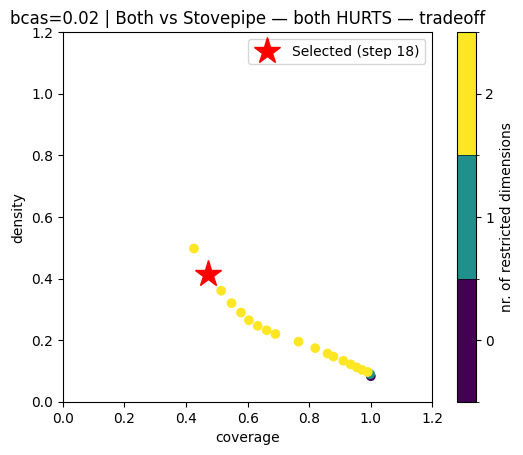


Selected step 18:
  coverage=0.471, density=0.413, mass=0.095
coverage       0.471469
density        0.413125
id            18.000000
k            661.000000
mass           0.094675
mean           0.413125
n           1600.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                                   
                       min   max       qp value      qp value
ccp_r1_same_bn_min    10.0  27.5            NaN  4.838985e-93
ccp_r1_inter_bn_min   52.5  70.0  4.771266e-106           NaN


Box limits:
  ccp_r1_same_bn_min: 10.00 — 27.50
  ccp_r1_inter_bn_min: 52.50 — 70.00

bcas=0.02 | Both vs Amb: both HURTS in 1707 / 16900 (10.1%)

Peeling trajectory (20 steps):
    coverage  density  mass  res_dim
0      1.000    0.101 1.000        0
1      0.995    0.109 0.923        1
2      0.977    0.117 0.846        1
3      0.951    0.123 0.781        2
4      0.927    0.131 0.716        2
5      0.915    0.142 0.651        2
6      0.909    0.157 0.586     

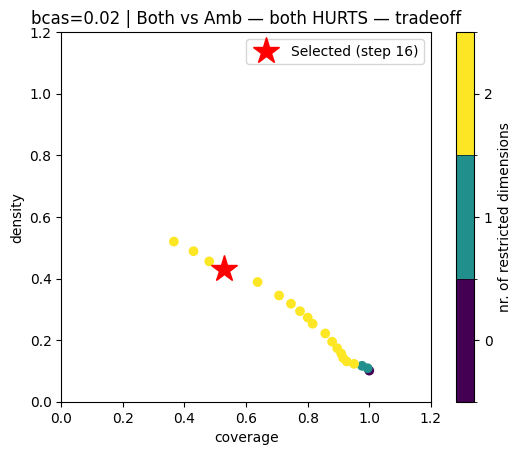


Selected step 16:
  coverage=0.530, density=0.430, mass=0.124
coverage       0.529584
density        0.430476
id            16.000000
k            904.000000
mass           0.124260
mean           0.430476
n           2100.000000
res_dim        2.000000
Name: 16, dtype: float64

                    box 16                                   
                       min   max       qp value      qp value
ccp_r1_inter_bn_min   10.0  42.5            NaN  1.738229e-50
ccp_r1_same_bn_min    57.5  70.0  1.777658e-203           NaN


Box limits:
  ccp_r1_same_bn_min: 57.50 — 70.00
  ccp_r1_inter_bn_min: 10.00 — 42.50

bcas=0.02 | Both vs Fac: both HURTS in 1493 / 16900 (8.8%)

Peeling trajectory (20 steps):
    coverage  density  mass  res_dim
0      1.000    0.088 1.000        0
1      0.995    0.095 0.923        1
2      0.979    0.102 0.852        2
3      0.953    0.108 0.781        2
4      0.924    0.114 0.716        2
5      0.906    0.123 0.651        2
6      0.879    0.133 0.586      

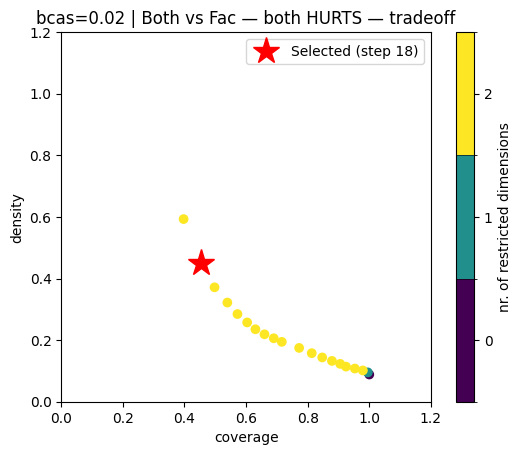


Selected step 18:
  coverage=0.452, density=0.450, mass=0.089
coverage       0.452110
density        0.450000
id            18.000000
k            675.000000
mass           0.088757
mean           0.450000
n           1500.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                                   
                       min   max      qp value       qp value
ccp_r1_same_bn_min    10.0  22.5           NaN  8.064902e-143
ccp_r1_inter_bn_min   47.5  70.0  9.368920e-68            NaN


Box limits:
  ccp_r1_same_bn_min: 10.00 — 22.50
  ccp_r1_inter_bn_min: 47.50 — 70.00

bcas=0.03: 16900 matched run pairs

bcas=0.03 | Both vs Stovepipe: both HURTS in 1784 / 16900 (10.6%)

Peeling trajectory (20 steps):
    coverage  density  mass  res_dim
0      1.000    0.106 1.000        0
1      0.996    0.114 0.923        1
2      0.976    0.122 0.846        1
3      0.956    0.129 0.781        2
4      0.928    0.137 0.716        2
5      0.896    0.145 0.651

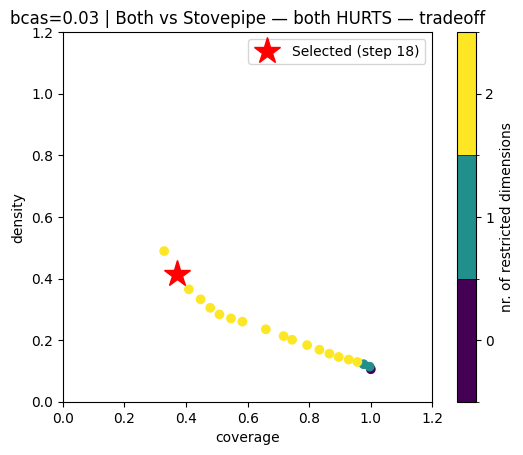


Selected step 18:
  coverage=0.371, density=0.413, mass=0.095
coverage       0.370516
density        0.413125
id            18.000000
k            661.000000
mass           0.094675
mean           0.413125
n           1600.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                                  
                       min   max      qp value      qp value
ccp_r1_same_bn_min    10.0  27.5           NaN  2.707663e-70
ccp_r1_inter_bn_min   52.5  70.0  8.323366e-81           NaN


Box limits:
  ccp_r1_same_bn_min: 10.00 — 27.50
  ccp_r1_inter_bn_min: 52.50 — 70.00

bcas=0.03 | Both vs Amb: both HURTS in 1490 / 16900 (8.8%)

Peeling trajectory (21 steps):
    coverage  density  mass  res_dim
0      1.000    0.088 1.000        0
1      0.993    0.095 0.923        1
2      0.970    0.101 0.846        1
3      0.946    0.108 0.769        1
4      0.910    0.116 0.692        1
5      0.885    0.122 0.639        2
6      0.845    0.131 0.568        2


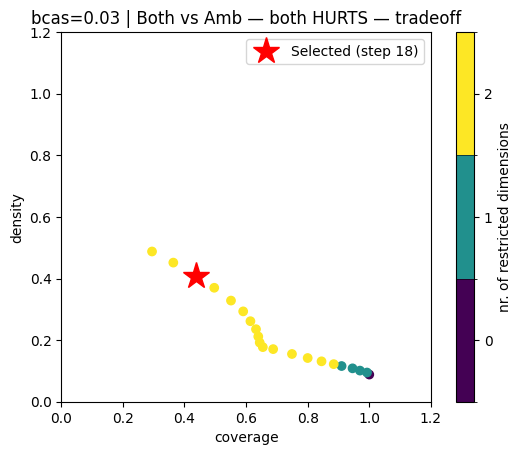


Selected step 18:
  coverage=0.437, density=0.407, mass=0.095
coverage       0.436913
density        0.406875
id            18.000000
k            651.000000
mass           0.094675
mean           0.406875
n           1600.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                                   
                       min   max       qp value      qp value
ccp_r1_same_bn_min    52.5  70.0  1.155803e-105           NaN
ccp_r1_inter_bn_min   17.5  37.5   8.378058e-12  1.054232e-74


Box limits:
  ccp_r1_same_bn_min: 52.50 — 70.00
  ccp_r1_inter_bn_min: 17.50 — 37.50

bcas=0.03 | Both vs Fac: both HURTS in 1858 / 16900 (11.0%)

Peeling trajectory (20 steps):
    coverage  density  mass  res_dim
0      1.000    0.110 1.000        0
1      0.991    0.118 0.923        1
2      0.973    0.125 0.852        2
3      0.948    0.133 0.781        2
4      0.911    0.141 0.710        2
5      0.874    0.148 0.651        2
6      0.843    0.157 0.592     

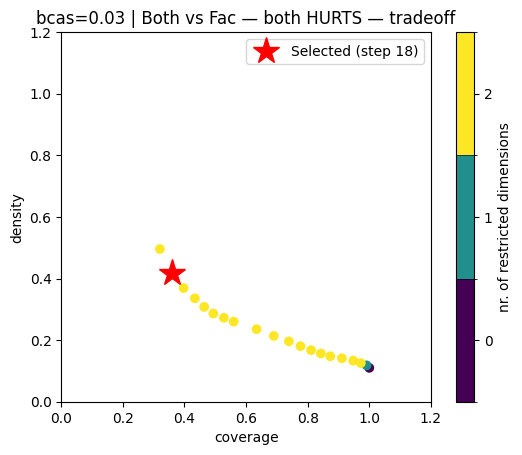


Selected step 18:
  coverage=0.360, density=0.418, mass=0.095
coverage       0.360065
density        0.418125
id            18.000000
k            669.000000
mass           0.094675
mean           0.418125
n           1600.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                                  
                       min   max      qp value      qp value
ccp_r1_same_bn_min    10.0  27.5           NaN  1.073417e-75
ccp_r1_inter_bn_min   52.5  70.0  2.340310e-66           NaN


Box limits:
  ccp_r1_same_bn_min: 10.00 — 27.50
  ccp_r1_inter_bn_min: 52.50 — 70.00


In [52]:
from ema_workbench.analysis import prim

BCAS_FILTER = [0.02, 0.03]

MATCH_COLS = ["seed", "bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
PRIM_DIMS  = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

for bcas in BCAS_FILTER:
    amb_f  = amb[amb["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    both_f = both[both["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    stove_f = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    fac_f  = fac[fac["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)

    assert (amb_f[MATCH_COLS].values == both_f[MATCH_COLS].values).all()
    print(f"\nbcas={bcas}: {len(both_f)} matched run pairs")

    x = both_f[PRIM_DIMS].astype(float).copy()

    comparisons = [
        ("Both vs Stovepipe", stove_f),
        ("Both vs Amb",       amb_f),
        ("Both vs Fac",       fac_f),
    ]

    for label, baseline in comparisons:
        delta = baseline["death_rate_T1_BCAS"].values - both_f["death_rate_T1_BCAS"].values
        both_hurts = delta < 0.0
        n_hurts = both_hurts.sum()
        print(f"\n{'='*60}")
        print(f"bcas={bcas} | {label}: both HURTS in {n_hurts} / {len(delta)} ({both_hurts.mean():.1%})")
        print(f"{'='*60}")

        if n_hurts < 10:
            print("Too few cases for PRIM.")
            continue

        p = prim.Prim(x, both_hurts, threshold=0.3, peel_alpha=0.05)
        box = p.find_box()

        traj = box.peeling_trajectory
        print(f"\nPeeling trajectory ({len(traj)} steps):")
        print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))

        best_idx = int(len(traj) - 1)
        for idx in range(len(traj)):
            if traj.iloc[idx]["density"] > 0.4 and traj.iloc[idx]["coverage"] > 0.2:
                best_idx = int(idx)
                break

        box.select(best_idx)
        box.show_tradeoff()
        sel = traj.iloc[best_idx]
        plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
        plt.legend()
        plt.title(f"bcas={bcas} | {label} — both HURTS — tradeoff")
        plt.show()

        print(f"\nSelected step {best_idx}:")
        print(f"  coverage={sel['coverage']:.3f}, density={sel['density']:.3f}, mass={sel['mass']:.3f}")
        box.inspect(best_idx)

        limits = box.box_lims[best_idx]
        print(f"\nBox limits:")
        for col in PRIM_DIMS:
            print(f"  {col}: {limits.iloc[0][col]:.2f} — {limits.iloc[1][col]:.2f}")